# 75. Matched checkpoint comparison: `002.27 best` vs `004.4 fine/coarse`

**Purpose.** Compare the original 6D rotation-head model (`002.27`) against the larger 3D rotation-vector model (`004.4`) on **exactly the same KAIST physical windows and injected rotation faults**. No training and no checkpoint modification.

The checkpoints have **different architectures**, not just different output heads:

| Component | `002.27 best` | `004.4 fine/coarse` |
| --- | --- | --- |
| Model class | `PooledCalibration6DModel` | `PooledCalibrationModel` |
| SO(3) prediction | `delta_rotation` (3×3 rotation matrix from 6D head) | `so3_exp(delta_xi[:, :3])` (3D rotation vector) |
| Transformer | `d_model=128`, 8 heads, 12 layers, FF=512 | `d_model=256`, 16 heads, 12 layers, FF=1024 |
| MLP | `(256, 128)` → 128 | `(512, 256)` → 256 |
| Pooler | 8 heads | 16 heads |
| Calibration head | `(128, 64)` | `(256, 128)` |
| Token input / measurement | 8 / 6 | 8 / 6 |
| Calibration context | disabled (`0`) | disabled (`0`) |

Each checkpoint is loaded into **its own model configuration**, with strict checkpoint compatibility enforced by the repository checkpoint loader. Both see identical canonical tokens and are evaluated in SO(3) with the same **left-multiplied correction** convention:

$$
R_{\rm after} = \widehat{\Delta R}\,R_{\rm before}, \qquad
\theta_{\rm residual} = d_{SO(3)}(R_{\rm after},R_{\rm truth}).
$$

**Outputs**

1. One-step residual vs initial error, correction magnitude, axis cosine and improvement rate, one figure per sensor × X/Y/Z/U1.
2. **12 consecutive 5-second windows**, closed-loop: each prediction updates the prior for the next physical window; one figure per sensor × axis, with 0°, 30°, 90°, 150° and 179° trajectories.
3. Case-matched differences (`004.4 minus 002.27`), win rates, mean/median/p90, zero-error drift, scatter plots, heatmaps and CSV exports.

Default: **validation** sequences `Urban26`, `Urban28`. `EVAL_SPLIT='test'` explicitly selects held-out `Urban38`, `Urban39`.

**Checkpoint selection:** `002.27` loads `best.pt`. `004.4` loads `last.pt` by default (the checkpoint referenced by notebook 74 when initializing `004.5`); change `NEW_CHECKPOINT_FILENAME` to `'best.pt'` to compare the best-validation checkpoint instead.

**Evaluation scope:** Perturbations are *rotation only* for one sensor at a time; translation and time offsets of the starting prior remain at synthetic physical truth. Only rotation predictions are applied during rollouts. This probes rotational convergence, not translation/time-offset recovery. The shared physical truth may be rotated and time-shifted by the noise-free augmentation pipeline, identically for both models.

## 1. Repository imports and the two checkpoint-specific model APIs

In [1]:
from pathlib import Path
from dataclasses import replace
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run this notebook inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp, so3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. All configurable evaluation settings

In [2]:
OLD_MODEL_NAME = '002.27 best'
NEW_MODEL_NAME = '004.4 best'

# Notebook 74 initializes from this run's last.pt. Change to 'best.pt' for its best-validation weights.
NEW_CHECKPOINT_FILENAME = 'best.pt'  # 'last.pt' or 'best.pt'
if NEW_CHECKPOINT_FILENAME not in ('best.pt', 'last.pt'):
    raise ValueError('NEW_CHECKPOINT_FILENAME must be best.pt or last.pt')

CHECKPOINTS = {
    OLD_MODEL_NAME: ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt',
    NEW_MODEL_NAME: ROOT / 'runs' / 'kaist_pooled_calibration_paired_004.4_fine_coarse' / NEW_CHECKPOINT_FILENAME,
}
MODEL_ORDER = (OLD_MODEL_NAME, NEW_MODEL_NAME)
COLORS = {OLD_MODEL_NAME: '#2563eb', NEW_MODEL_NAME: '#ea580c'}
DELTA_COLUMN = 'delta_new_minus_old_deg'  # Negative means the newer checkpoint is better.

EVAL_SPLIT = 'validation'  # 'validation' or 'test'
if EVAL_SPLIT not in ('validation', 'test'):
    raise ValueError('EVAL_SPLIT must be validation or test')
EVAL_SEQUENCES = {'validation': ('Urban26', 'Urban28'), 'test': ('Urban38', 'Urban39')}[EVAL_SPLIT]
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
OUTPUT_DIR = ROOT / 'runs' / ('checkpoint_comparison_00227_best_vs_0044_' + NEW_CHECKPOINT_FILENAME.removesuffix('.pt')) / EVAL_SPLIT

RANDOM_SEED = 12345
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32

# PyTorch NestedTensor evaluation fastpath can fail with variable-length sensor token batches.
DISABLE_MHA_FASTPATH = True
if DISABLE_MHA_FASTPATH and hasattr(torch.backends, 'mha'):
    torch.backends.mha.set_fastpath_enabled(False)

CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
ANGLES_DEG = (0., 15., 30., 60., 90., 120., 150., 175., 179.)
AXIS_NAMES = ('X', 'Y', 'Z', 'U1')
AXIS_SEED = 650_272  # Reproduce DIAG65 U1 direction.
FAULT_KEYS = CALIBRATION_KEYS

# Identical physical truth for both models. No artificial measurement noise.
TRUE_CALIBRATION_ROTATION_MAX_DEG = 180.0
TRUE_CALIBRATION_TAU_MAX_S = 0.030  # 0.0 disables synthetic true tau shifts.

ONE_STEP_WINDOWS_PER_SEQUENCE = 12
ONE_STEP_BATCH_SIZE = 4  # Reduce if the 256-D Transformer exhausts GPU memory.
ONE_STEP_PHYSICAL_SEED = 650_271

ROLLOUT_NUM_WINDOWS = 12
ROLLOUT_STARTS_PER_SEQUENCE = 2  # Never cross a sequence boundary.
ROLLOUT_CASE_BATCH_SIZE = 4      # Reduce for small GPUs; same case bank is used by both models.
ROLLOUT_PHYSICAL_SEED = 650_273
ROLLOUT_UPDATE_ALL_KEYS = False  # False: update only perturbed sensor. True: also update healthy sensors.
ROLLOUT_TRACE_ANGLES = (0., 30., 90., 150., 179.)

SHOW_PLOTS = True
SAVE_PLOTS = True
PLOT_DPI = 155

for name, path in CHECKPOINTS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{name}: checkpoint not found: {path}')
if not set(FAULT_KEYS).issubset(CALIBRATION_KEYS):
    raise ValueError('FAULT_KEYS contains an unknown calibration key')
if ROLLOUT_CASE_BATCH_SIZE < 1 or ROLLOUT_NUM_WINDOWS < 1 or ONE_STEP_BATCH_SIZE < 1:
    raise ValueError('Batch sizes and rollout horizon must be positive')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
print('Checkpoint comparison:')
for name, path in CHECKPOINTS.items():
    print(f'  {name:20s} -> {path}')
print('Evaluation:', EVAL_SPLIT, EVAL_SEQUENCES, '| device:', DEVICE, '| output:', OUTPUT_DIR)

Checkpoint comparison:
  002.27 best          -> /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
  004.4 best           -> /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_004.4_fine_coarse/best.pt
Evaluation: validation ('Urban26', 'Urban28') | device: cuda | output: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/checkpoint_comparison_00227_best_vs_0044_best/validation


## 3. KAIST rig, corrected clock offsets and held-out dataset

In [3]:
# Exact KAIST extrinsics and time references from the earlier 57/65/66 notebooks.
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=list(EVAL_SEQUENCES), kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR map poses for {spec.name}: {spec.lidar_right_pose_csv}')

eval_dataset = KAISTCalibrationDataset(all_specs, rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
assert tuple(eval_dataset.calibration_keys) == CALIBRATION_KEYS
for name in EVAL_SEQUENCES:
    selected = eval_dataset.window_indices_for_sequence(name)
    if len(selected) < ROLLOUT_NUM_WINDOWS:
        raise ValueError(f'Not enough windows for {name}: {len(selected)} < {ROLLOUT_NUM_WINDOWS}')
print(eval_dataset.summary())

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658


## 4. Identical augmentation and SO(3) measurement conventions

In [4]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)


def seeded_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def distance_so3_deg(R_a, R_b):
    """Stable SO(3) angle, including near identity and 179 degrees."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[...,2,1]-R[...,1,2], R[...,0,2]-R[...,2,0], R[...,1,0]-R[...,0,1]), dim=-1)
    sin_theta = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_theta = 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)
    return torch.rad2deg(torch.atan2(sin_theta, cos_theta))


def copy_states(states):
    return {key: CalibrationState(transform=x.transform.detach().clone(), time_offset=x.time_offset.detach().clone()) for key, x in states.items()}


def with_states(physical_window, states):
    return WindowBatch(streams=dict(physical_window.streams), current_calibration=states,
                       metadata=dict(physical_window.metadata), targets=None,
                       dataset_indices=physical_window.dataset_indices)


def faulted_prior(truth_states, fault_key, axis, signed_angle_deg):
    """Pure left-composed SO(3) fault, no translation or tau perturbation."""
    result = copy_states(truth_states)
    state = result[fault_key]
    R = so3_exp(axis[None, :] * np.deg2rad(float(signed_angle_deg)))
    T = state.transform.clone()
    T[:, :3, :3] = R @ state.transform[:, :3, :3]
    result[fault_key] = replace(state, transform=T)
    return result


def make_axes():
    axes = {
        'X': torch.tensor([1.,0.,0.], device=DEVICE, dtype=MODEL_DTYPE),
        'Y': torch.tensor([0.,1.,0.], device=DEVICE, dtype=MODEL_DTYPE),
        'Z': torch.tensor([0.,0.,1.], device=DEVICE, dtype=MODEL_DTYPE),
    }
    gen = seeded_generator(AXIS_SEED)
    u1 = torch.randn(3, device=DEVICE, dtype=MODEL_DTYPE, generator=gen)
    axes['U1'] = u1 / u1.norm().clamp_min(1e-12)
    return axes

AXES = make_axes()
print('Axis definitions:', {name: axis.detach().cpu().numpy().round(5) for name, axis in AXES.items()})
# assert abs(float(distance_so3_deg(so3_exp(torch.tensor([[0., 0., np.deg2rad(179.)]], device=DEVICE)), torch.eye(3, device=DEVICE).unsqueeze(0))[0]) - 179.0) < 0.05

Axis definitions: {'X': array([1., 0., 0.], dtype=float32), 'Y': array([0., 1., 0.], dtype=float32), 'Z': array([0., 0., 1.], dtype=float32), 'U1': array([ 0.03957,  0.57054, -0.82032], dtype=float32)}


## 5. Construct and load **each** checkpoint with its own architecture

In [5]:
# The 002.27 architecture comes from the original comparison notebook (68).
# The 004.4 architecture comes from its training notebook (73) and matches the dimensions requested.
MODEL_ARCHITECTURES = {
    OLD_MODEL_NAME: dict(
        model_class=PooledCalibration6DModel, measurement_dim=6, token_input_dim=8,
        d_model=128, n_heads=8, num_layers=12, dim_feedforward=512,
        transformer_dropout=0.0, num_summary_tokens=1,
        pooler_n_heads=8, pooler_dropout=0.0,
        mlp_hidden_dims=(256, 128), shared_feature_dim=128, mlp_dropout=0.0,
        head_hidden_dims=(128, 64), head_dropout=0.0,
    ),
    NEW_MODEL_NAME: dict(
        model_class=PooledCalibrationModel, measurement_dim=6, token_input_dim=8,
        d_model=256, n_heads=16, num_layers=12, dim_feedforward=1024,
        transformer_dropout=0.0, num_summary_tokens=1,
        pooler_n_heads=16, pooler_dropout=0.0,
        mlp_hidden_dims=(512, 256), shared_feature_dim=256, mlp_dropout=0.0,
        head_hidden_dims=(256, 128), head_dropout=0.0,
    ),
}


def build_model_config(arch):
    """Instantiate exact pooled calibration dimensions without reusing the other model's config."""
    return PooledCalibrationModelConfig(
        transformer=TransformerConfig(
            input_dim=arch['token_input_dim'], d_model=arch['d_model'], n_heads=arch['n_heads'],
            num_layers=arch['num_layers'], dim_feedforward=arch['dim_feedforward'],
            dropout=arch['transformer_dropout'], num_summary_tokens=arch['num_summary_tokens'], activation='gelu',
        ),
        mlp=MLPConfig(
            hidden_dims=arch['mlp_hidden_dims'], output_dim=arch['shared_feature_dim'],
            activation='gelu', dropout=arch['mlp_dropout'],
        ),
        pooler=CalibrationPoolerConfig(
            n_heads=arch['pooler_n_heads'], dropout=arch['pooler_dropout'], calibration_context_dim=0,
        ),
        head=PooledCalibrationHeadConfig(
            calibration_context_dim=0, hidden_dims=arch['head_hidden_dims'],
            activation='gelu', dropout=arch['head_dropout'],
        ),
    )


models = {}
for model_name in MODEL_ORDER:
    arch = MODEL_ARCHITECTURES[model_name]
    if arch['measurement_dim'] != 6 or arch['token_input_dim'] != arch['measurement_dim'] + 2:
        raise AssertionError(f'{model_name}: incompatible canonical token dimensions')
    model_config = build_model_config(arch)
    candidate = arch['model_class'](model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
    try:
        load_training_checkpoint(CHECKPOINTS[model_name], model=candidate, map_location=DEVICE, restore_rng_state=False)
    except (RuntimeError, ValueError, KeyError) as error:
        raise RuntimeError(
            f'Failed to load {model_name} using its dedicated model configuration. '
            f'Check architecture and checkpoint choice: {CHECKPOINTS[model_name]}'
        ) from error
    candidate.eval().requires_grad_(False)
    models[model_name] = candidate
    print(f'{model_name}: {type(candidate).__name__}, d_model={arch["d_model"]}, '
          f'transformer_heads={arch["n_heads"]}, pooler_heads={arch["pooler_n_heads"]}, '
          f'parameters={sum(param.numel() for param in candidate.parameters()):,}')


@torch.inference_mode()
def predicted_rotation_matrices(window, candidate_name):
    """Run canonical sensor tokens through the specified model; return SO(3) left-corrections."""
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer(streams, calibration_keys=tuple(window.current_calibration))
    predictions = models[candidate_name](tokens).predictions
    if candidate_name == OLD_MODEL_NAME:
        return {key: predictions[key].delta_rotation for key in CALIBRATION_KEYS}
    return {key: so3_exp(predictions[key].delta_xi[:, :3]) for key in CALIBRATION_KEYS}


@torch.inference_mode()
def smoke_compare_interfaces():
    raw = window_batch_to(collate_windows([eval_dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
    physical = physical_augmenter(raw, generator=seeded_generator(117)).augmented_window
    window = with_states(physical, physical.current_calibration)
    for model_name in MODEL_ORDER:
        rotations = predicted_rotation_matrices(window, model_name)
        for key in CALIBRATION_KEYS:
            R = rotations[key]
            assert R.shape == (1, 3, 3), (model_name, key, R.shape)
            assert bool(torch.isfinite(R).all()), (model_name, key, 'nonfinite rotation')
            torch.testing.assert_close(R @ R.transpose(-1, -2), torch.eye(3, device=DEVICE).unsqueeze(0), atol=5e-4, rtol=5e-4)
    print('Both different-size checkpoints loaded and passed the SO(3) interface smoke test.')


smoke_compare_interfaces()

002.27 best: PooledCalibration6DModel, d_model=128, transformer_heads=8, pooler_heads=8, parameters=2,554,570
004.4 best: PooledCalibrationModel, d_model=256, transformer_heads=16, pooler_heads=16, parameters=10,171,657
Both different-size checkpoints loaded and passed the SO(3) interface smoke test.


## 6. Matched one-step correction cases

In [6]:
@torch.inference_mode()
def build_one_step_physical_bank():
    bank = []
    for seq_idx, name in enumerate(EVAL_SEQUENCES):
        indices = np.asarray(eval_dataset.window_indices_for_sequence(name), dtype=int)
        selected = np.unique(np.linspace(0, len(indices)-1, min(ONE_STEP_WINDOWS_PER_SEQUENCE, len(indices))).round().astype(int))
        for batch_index, start in enumerate(range(0, len(selected), ONE_STEP_BATCH_SIZE)):
            chosen = indices[selected[start:start + ONE_STEP_BATCH_SIZE]]
            base = window_batch_to(collate_windows([eval_dataset[int(i)] for i in chosen]), DEVICE, dtype=MODEL_DTYPE)
            physical = physical_augmenter(base, generator=seeded_generator(ONE_STEP_PHYSICAL_SEED + seq_idx*100003 + batch_index*1009)).augmented_window
            bank.append(dict(sequence=name, indices=chosen, window=physical))
    return bank

one_step_bank = build_one_step_physical_bank()
print('Matched physical one-step windows:', sum(len(item['indices']) for item in one_step_bank), '| batches:', len(one_step_bank))


@torch.inference_mode()
def evaluate_one_step():
    rows = []
    for bank_index, item in enumerate(one_step_bank):
        physical = item['window']
        truth = physical.current_calibration
        batch_size = len(item['indices'])
        for key in FAULT_KEYS:
            R_true = truth[key].transform[:, :3, :3]
            for axis_name in AXIS_NAMES:
                axis = AXES[axis_name]
                for angle in ANGLES_DEG:
                    for sign in ((1,) if angle == 0 else (-1,1)):
                        prior = faulted_prior(truth, key, axis, sign * angle)
                        R_before = prior[key].transform[:, :3, :3]
                        before = distance_so3_deg(R_before, R_true)
                        if not bool((before - angle).abs().max() < 0.2):
                            raise AssertionError(f'Invalid fault: {key}, {axis_name}, {angle}, {sign}: {before}')
                        window = with_states(physical, prior)
                        R_target = R_true @ R_before.transpose(-1,-2)
                        phi_target = so3_log(R_target)
                        for model_name in MODEL_ORDER:
                            R_correction = predicted_rotation_matrices(window, model_name)[key]
                            R_after = R_correction @ R_before
                            residual = distance_so3_deg(R_after, R_true)
                            predicted_magnitude = distance_so3_deg(R_correction, torch.eye(3,device=DEVICE,dtype=MODEL_DTYPE).expand_as(R_correction))
                            phi_pred = so3_log(R_correction)
                            cos = F.cosine_similarity(phi_pred, phi_target, dim=-1)
                            cos = torch.where((phi_pred.norm(dim=-1) > np.deg2rad(1.0)) & (phi_target.norm(dim=-1) > np.deg2rad(1.0)), cos, torch.nan)
                            for j, physical_index in enumerate(item['indices']):
                                a, b = float(before[j]), float(residual[j])
                                rows.append(dict(model=model_name, sequence=item['sequence'], physical_index=int(physical_index), sensor=key,
                                                 axis=axis_name, sign=int(sign), angle_deg=float(angle), initial_deg=a,
                                                 residual_deg=b, gain_deg=a-b, predicted_magnitude_deg=float(predicted_magnitude[j]),
                                                 axis_cos=float(cos[j]), improved=bool(b < a - 1e-4), success_10deg=bool(b<10)))
        print(f'One-step physical batch {bank_index+1}/{len(one_step_bank)}: {item["sequence"]}', flush=True)
    result = pd.DataFrame(rows)
    result.to_csv(OUTPUT_DIR / 'one_step_cases.csv', index=False)
    return result

one_step_df = evaluate_one_step()
one_step_summary = one_step_df.groupby(['model','sensor','axis','angle_deg'], as_index=False).agg(
    n=('residual_deg','size'), mean_residual_deg=('residual_deg','mean'), median_residual_deg=('residual_deg','median'),
    p90_residual_deg=('residual_deg',lambda x: np.percentile(x,90)), predicted_magnitude_deg=('predicted_magnitude_deg','mean'),
    axis_cos=('axis_cos','mean'), improved_fraction=('improved','mean'), success_10deg=('success_10deg','mean'))
one_step_summary.to_csv(OUTPUT_DIR / 'one_step_summary.csv', index=False)
print('One-step cases:', len(one_step_df), '| expected equal count per checkpoint:', one_step_df.groupby('model').size().to_dict())
display(one_step_summary[one_step_summary.angle_deg.isin((0.,30.,90.,150.,179.))].round(2).head(30))

Matched physical one-step windows: 24 | batches: 6
One-step physical batch 1/6: Urban26
One-step physical batch 2/6: Urban26
One-step physical batch 3/6: Urban26
One-step physical batch 4/6: Urban28
One-step physical batch 5/6: Urban28
One-step physical batch 6/6: Urban28
One-step cases: 9792 | expected equal count per checkpoint: {'002.27 best': 4896, '004.4 best': 4896}


,model,sensor,axis,angle_deg,n,mean_residual_deg,median_residual_deg,p90_residual_deg,predicted_magnitude_deg,axis_cos,improved_fraction,success_10deg
0,002.27 best,imu,U1,0.0,24,0.59,0.26,1.23,0.59,NaN,0.00,1.00
2,002.27 best,imu,U1,30.0,48,8.29,5.94,17.10,26.82,0.95,0.98,0.75
4,002.27 best,imu,U1,90.0,48,31.38,23.13,57.94,79.66,0.88,0.94,0.15
6,002.27 best,imu,U1,150.0,48,148.34,155.64,173.19,80.45,-0.07,0.40,0.00
8,002.27 best,imu,U1,179.0,48,160.11,163.31,173.95,77.35,-0.01,1.00,0.00
9,002.27 best,imu,X,0.0,24,0.59,0.26,1.23,0.59,NaN,0.00,1.00
11,002.27 best,imu,X,30.0,48,5.64,5.58,7.51,26.73,0.99,1.00,0.98
13,002.27 best,imu,X,90.0,48,11.81,10.51,18.36,97.23,0.99,1.00,0.46
15,002.27 best,imu,X,150.0,48,51.90,46.46,69.50,113.87,0.93,1.00,0.00
17,002.27 best,imu,X,179.0,48,166.68,170.02,178.49,122.93,0.07,0.96,0.00


## 7. One-step plots, one figure per sensor and axis

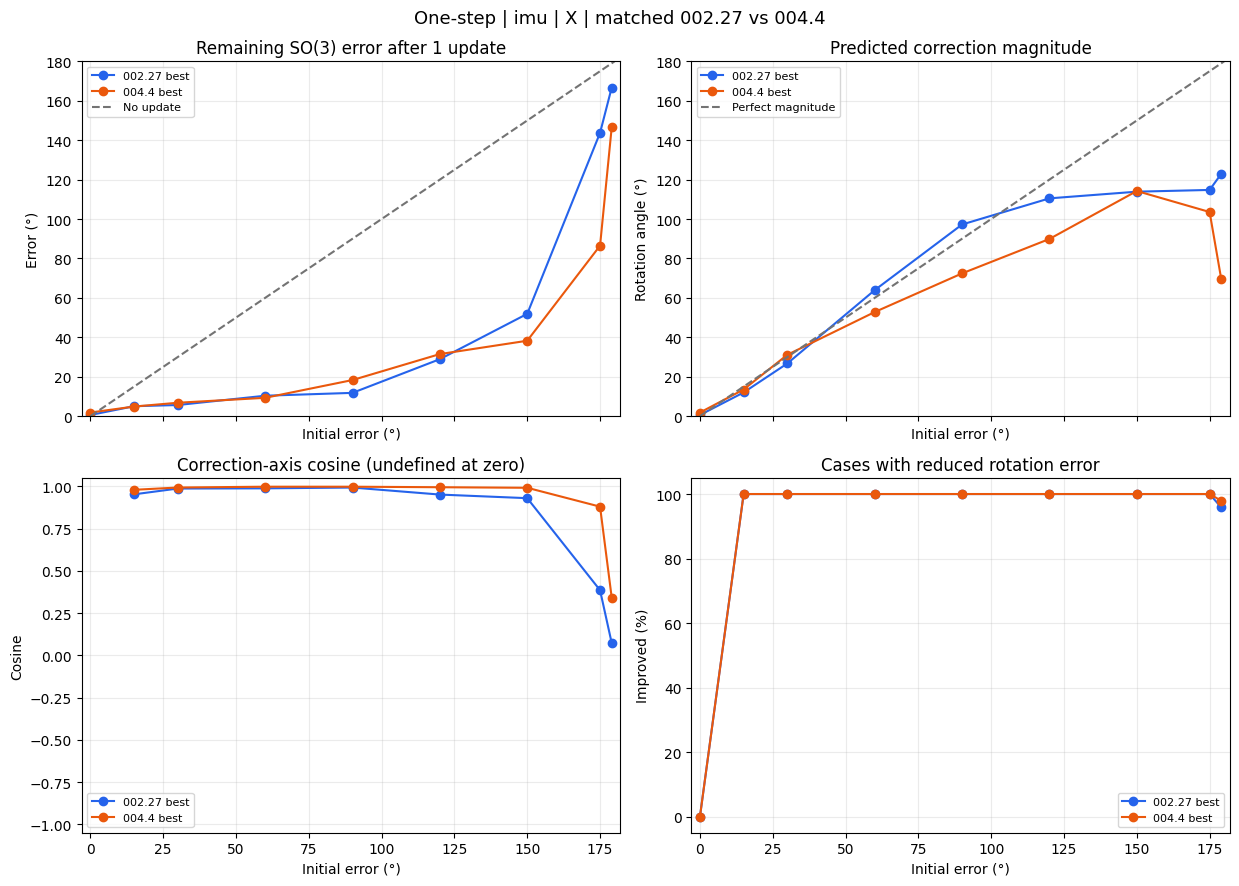

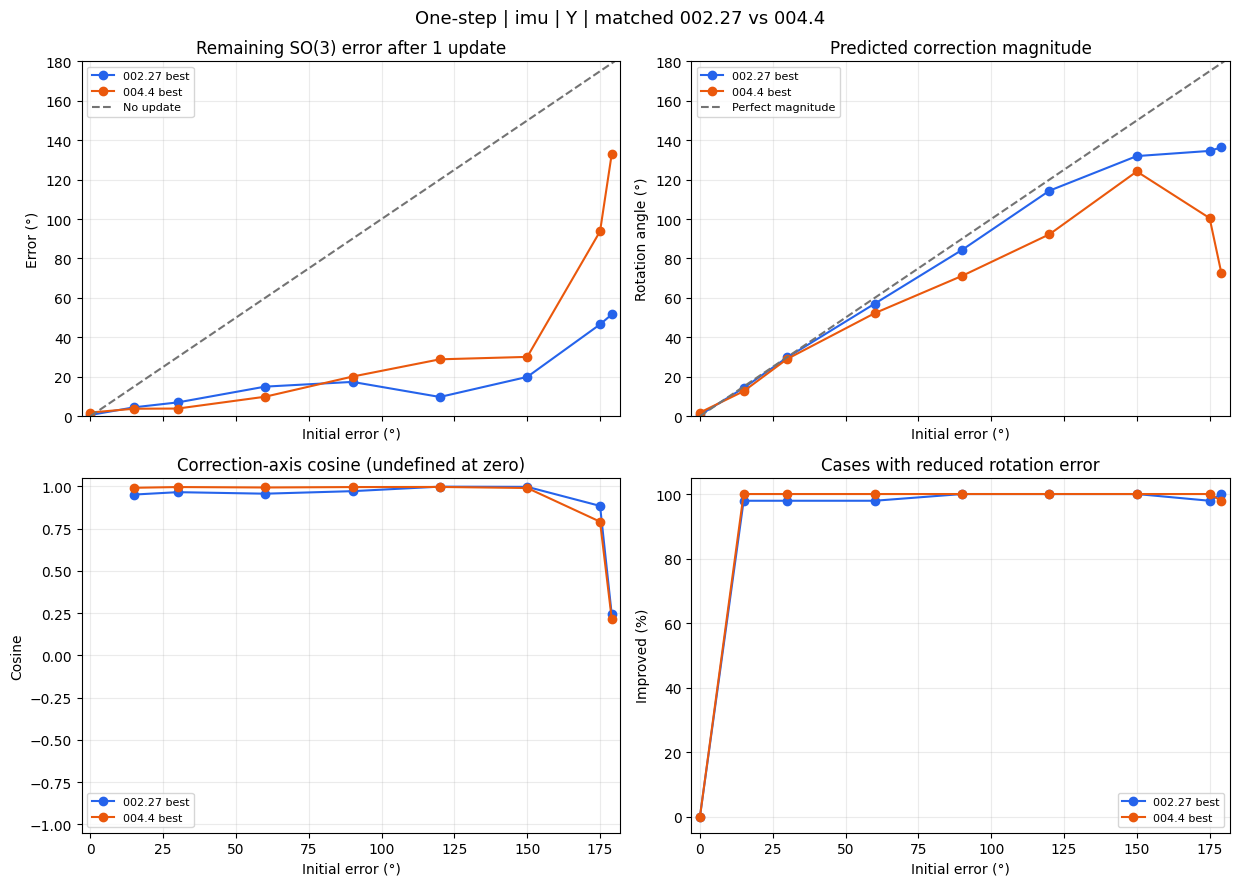

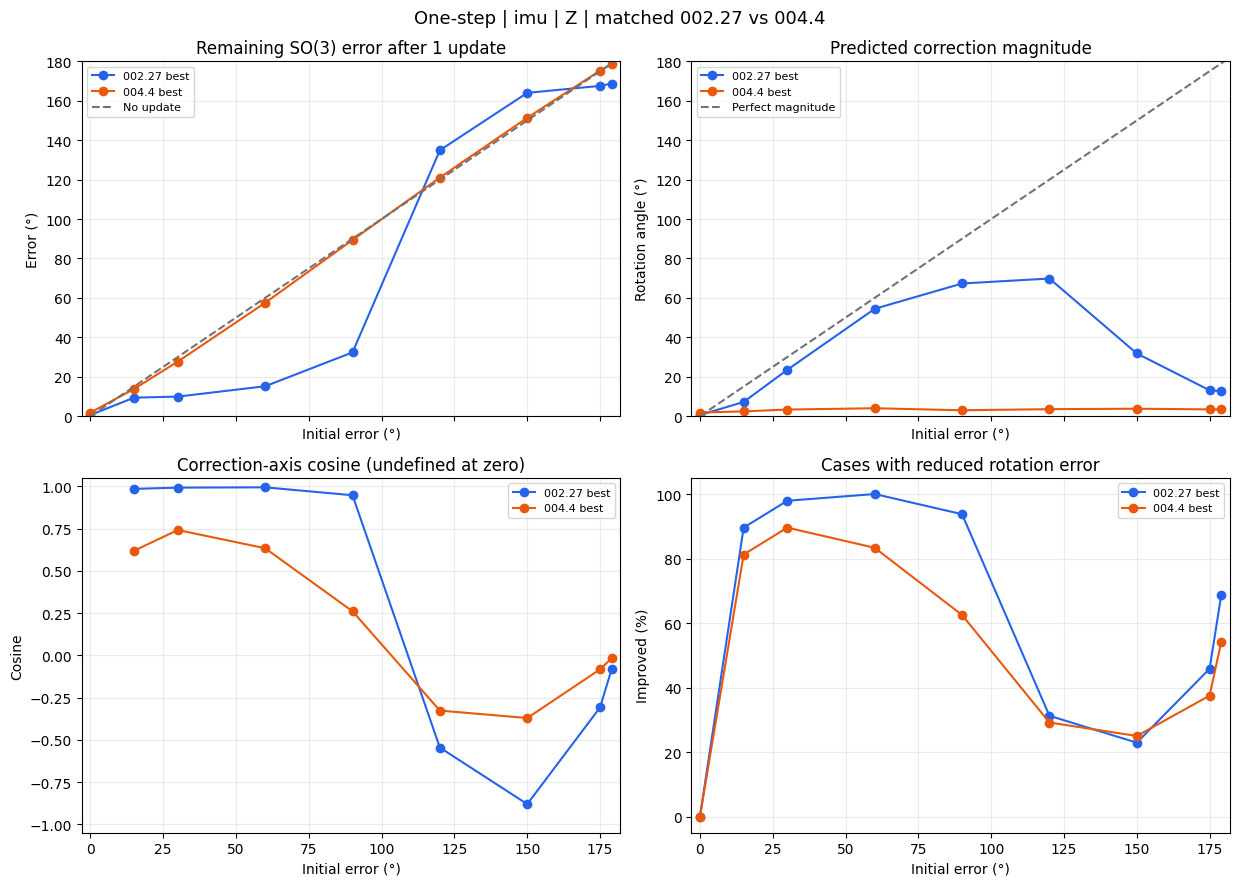

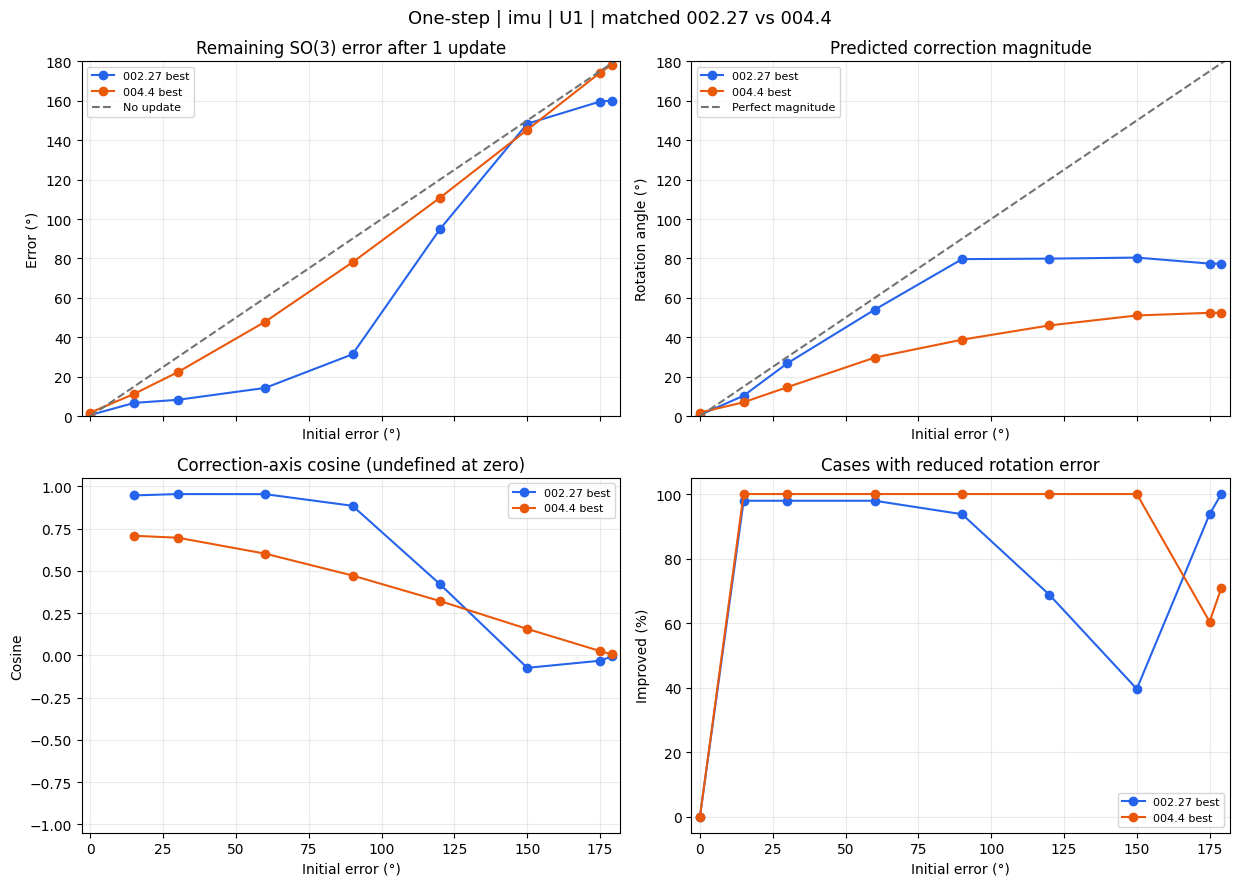

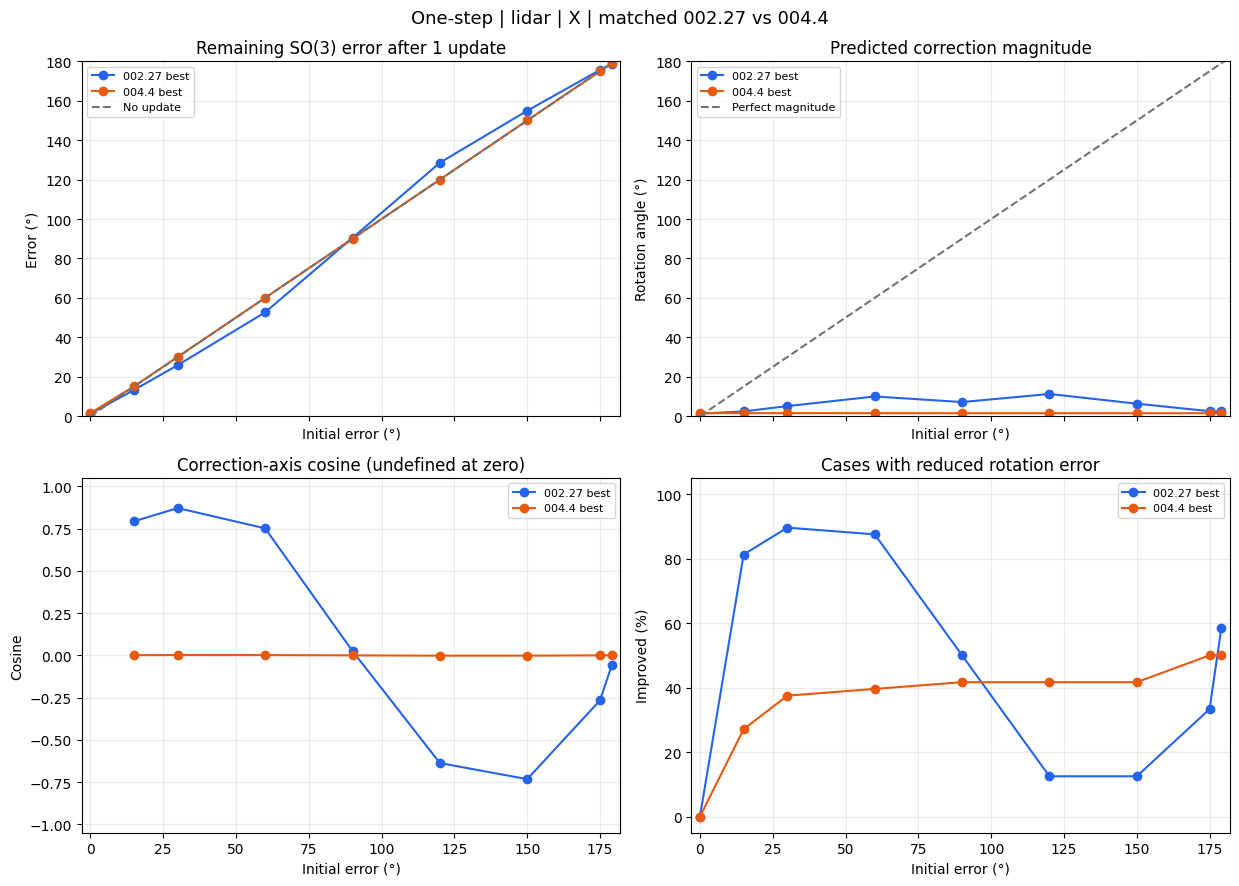

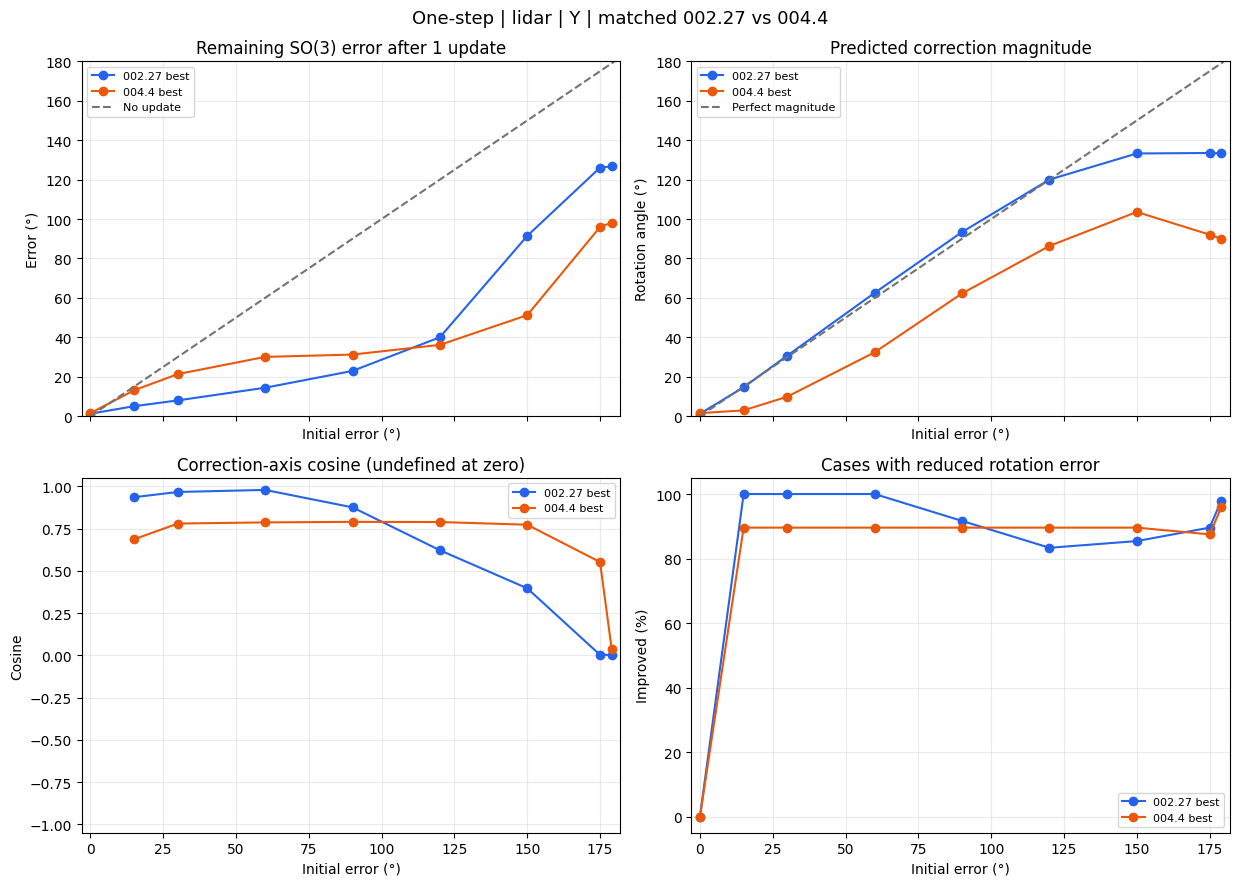

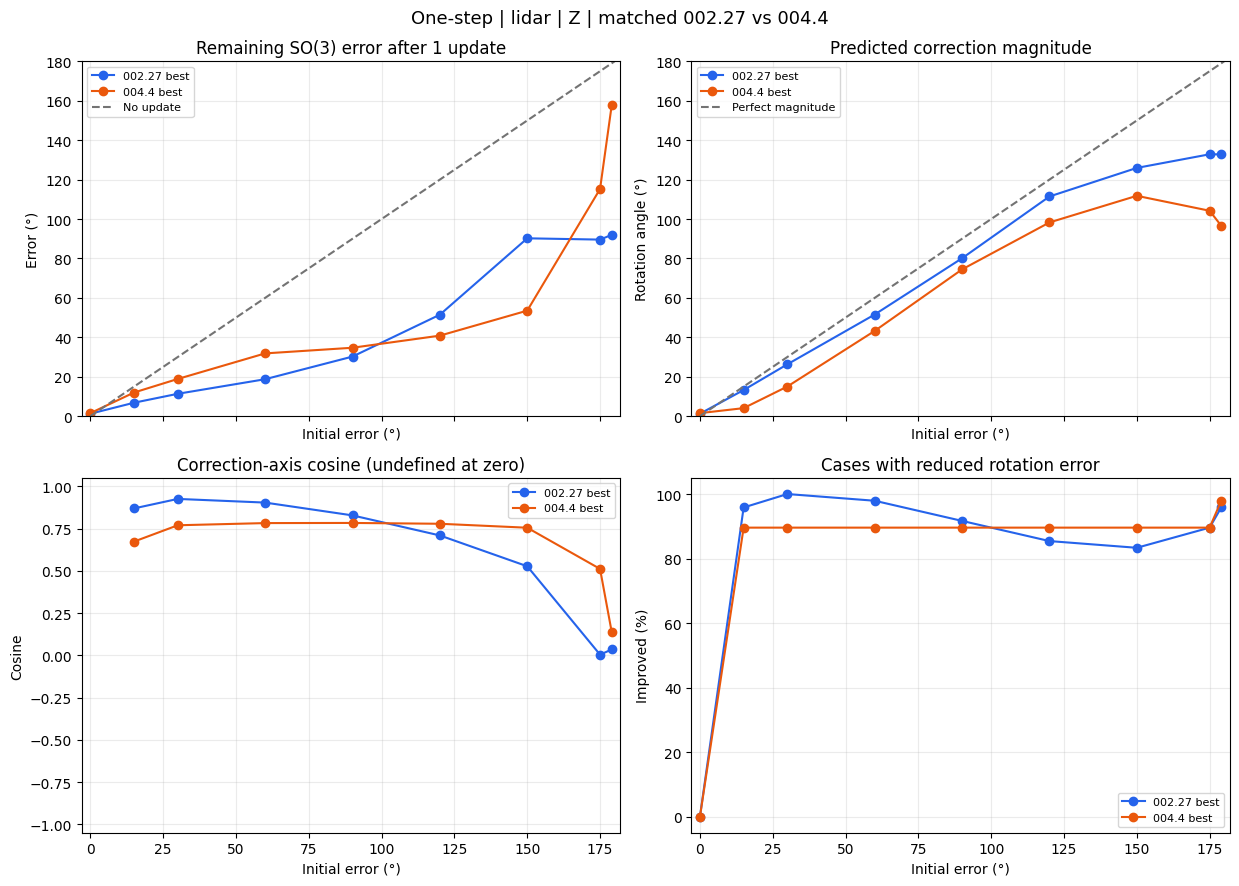

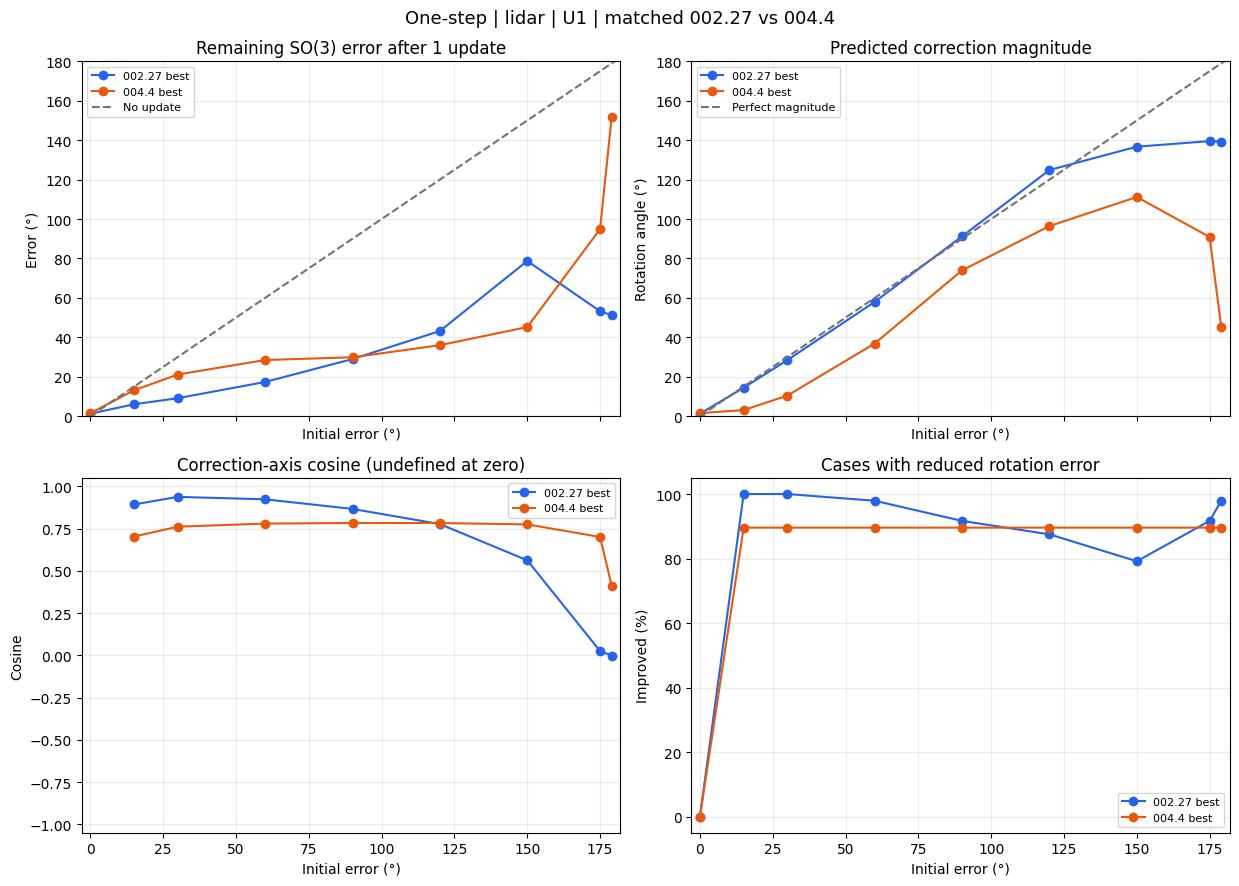

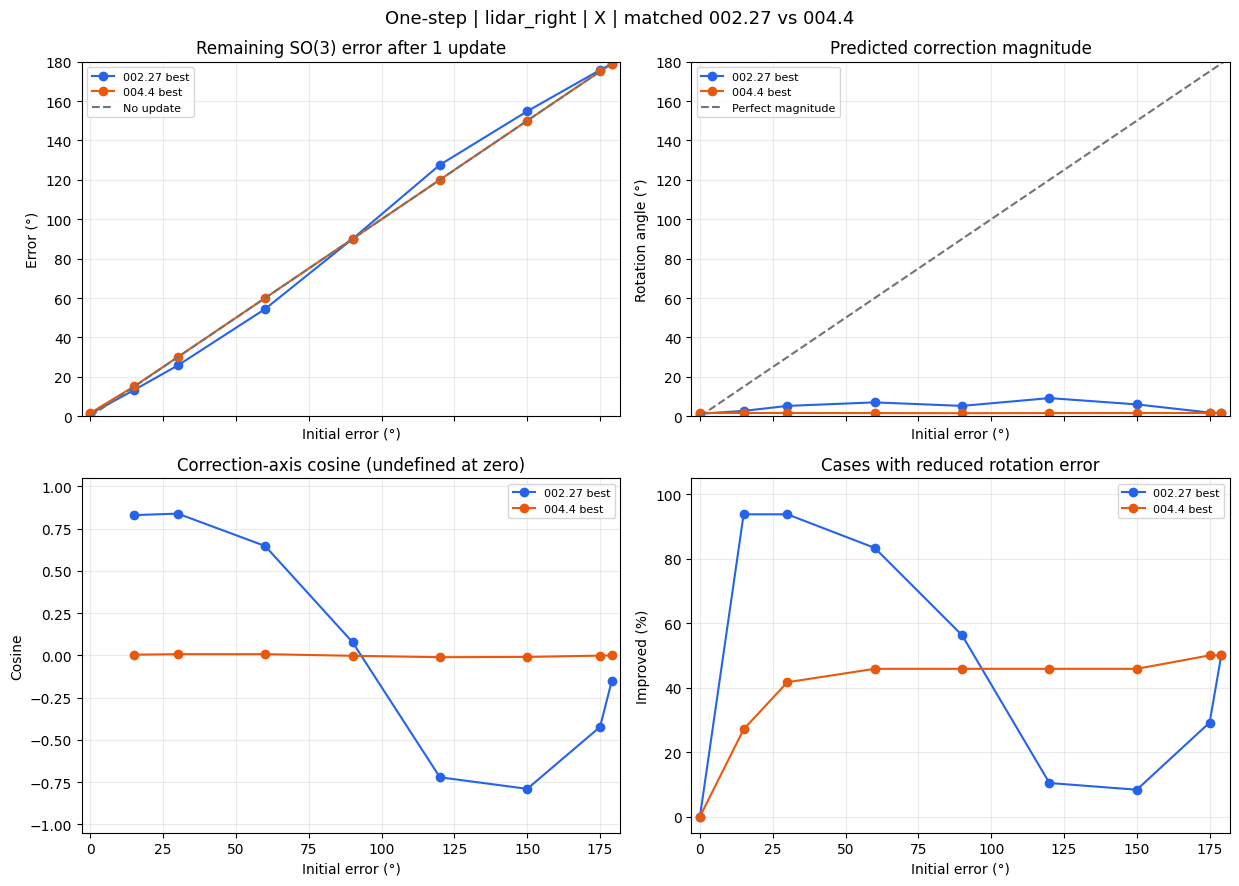

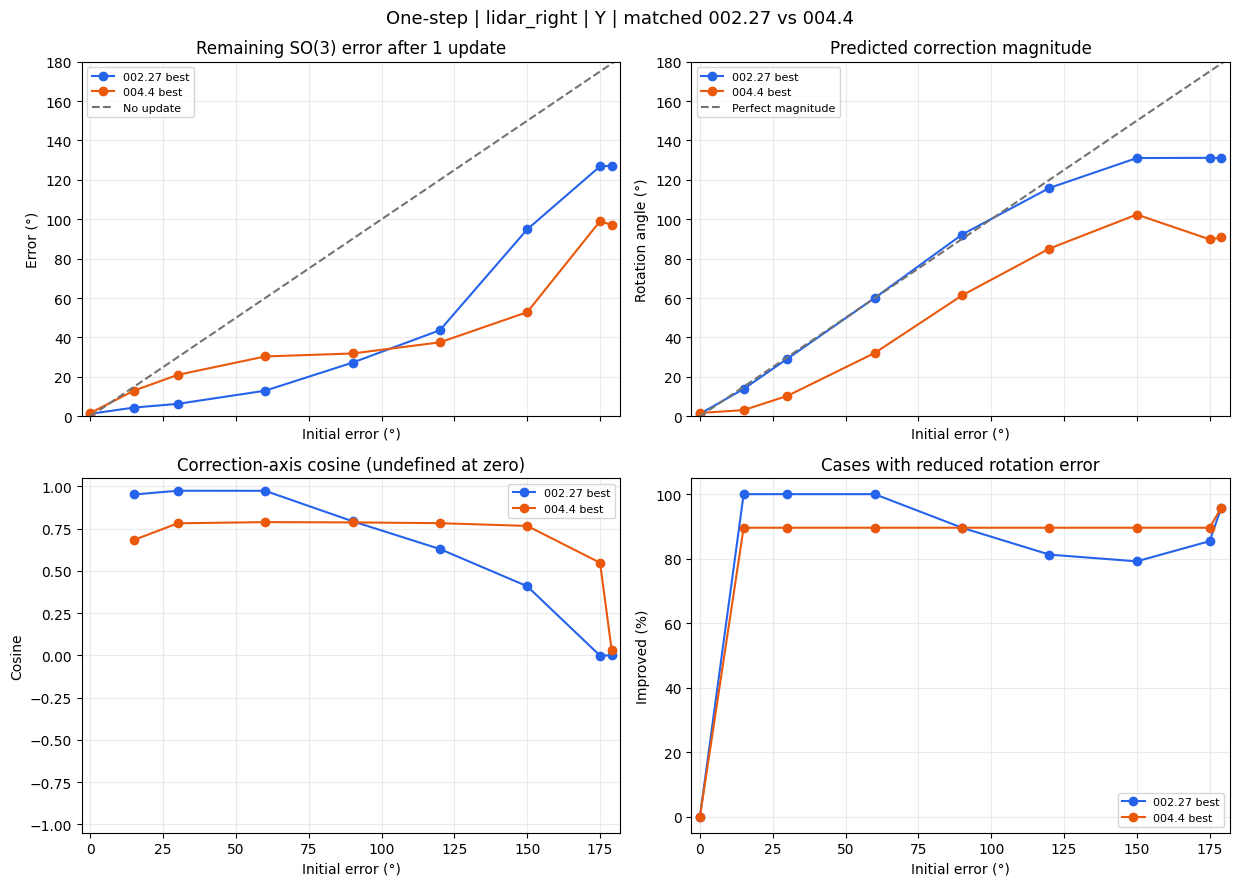

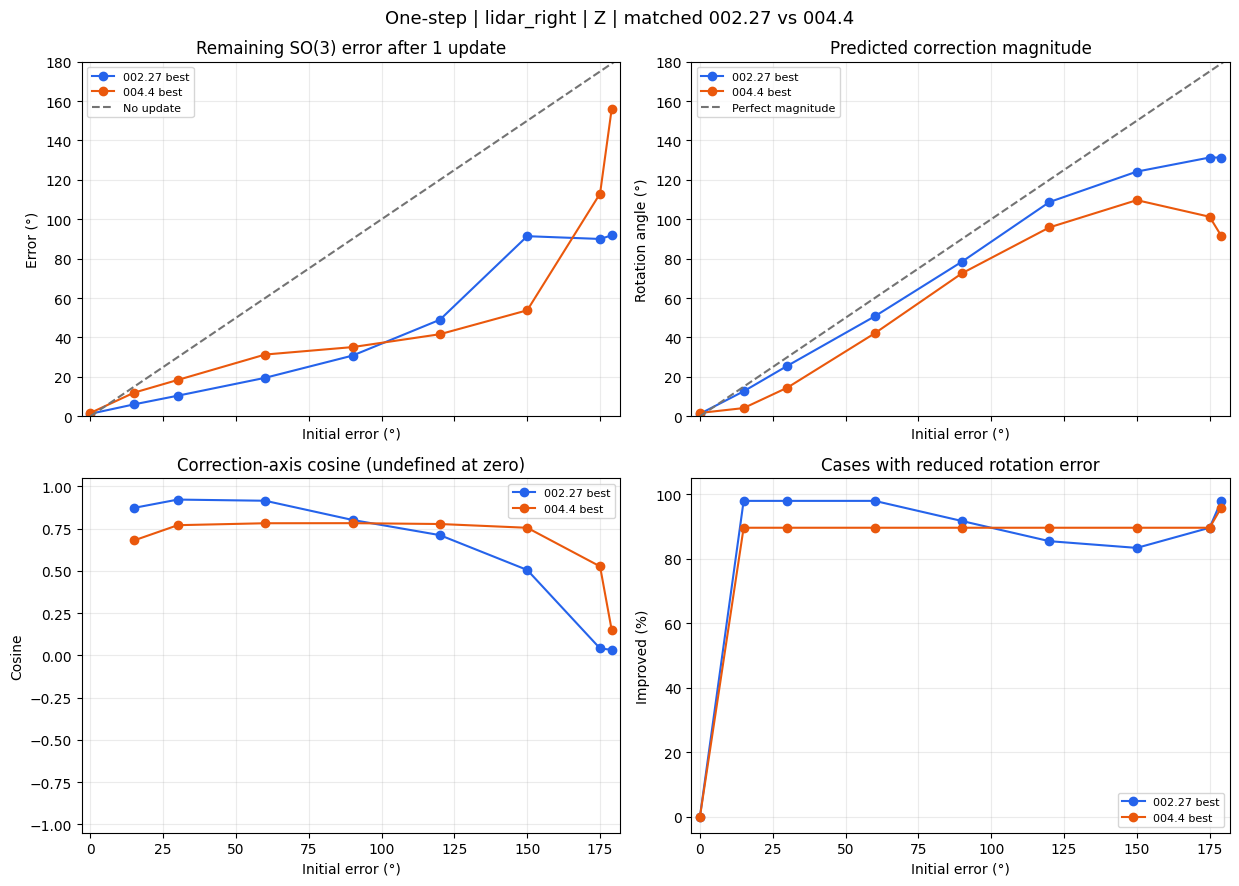

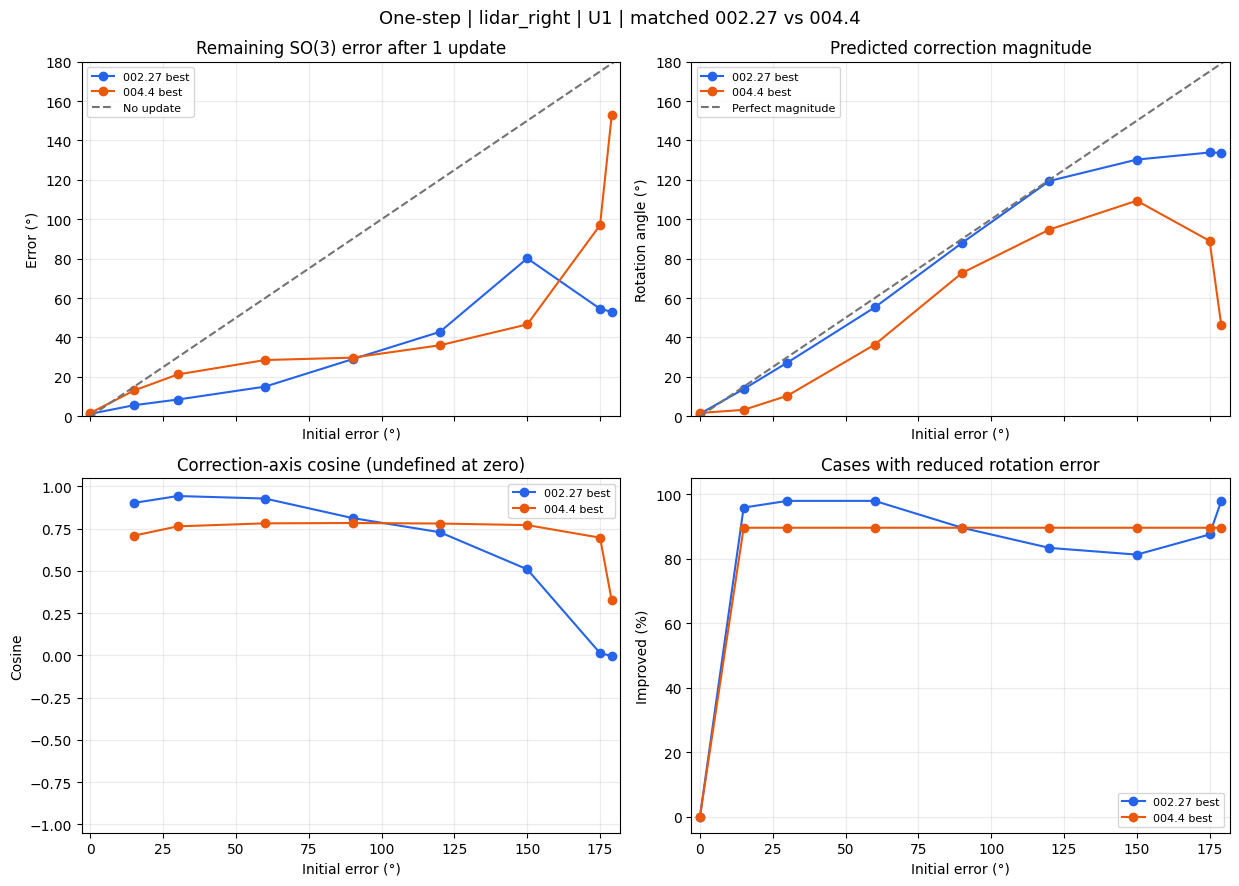

In [7]:
def finish_figure(fig, filename):
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(OUTPUT_DIR / filename, dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


for sensor in FAULT_KEYS:
    for axis_name in AXIS_NAMES:
        fig, axs = plt.subplots(2,2,figsize=(12.5,9.0),sharex=True)
        for name in MODEL_ORDER:
            curve = one_step_summary[(one_step_summary.model==name)&(one_step_summary.sensor==sensor)&(one_step_summary.axis==axis_name)].sort_values('angle_deg')
            x = curve.angle_deg.to_numpy()
            axs[0,0].plot(x,curve.mean_residual_deg,'-o',color=COLORS[name],label=name)
            axs[0,1].plot(x,curve.predicted_magnitude_deg,'-o',color=COLORS[name],label=name)
            axs[1,0].plot(x,curve.axis_cos,'-o',color=COLORS[name],label=name)
            axs[1,1].plot(x,100*curve.improved_fraction,'-o',color=COLORS[name],label=name)
        for ax in (axs[0,0],axs[0,1]):
            ax.plot([0,180],[0,180],'--',color='0.45',label='No update' if ax is axs[0,0] else 'Perfect magnitude')
        axs[0,0].set(title='Remaining SO(3) error after 1 update',ylabel='Error (°)',ylim=(0,180))
        axs[0,1].set(title='Predicted correction magnitude',ylabel='Rotation angle (°)',ylim=(0,180))
        axs[1,0].set(title='Correction-axis cosine (undefined at zero)',ylabel='Cosine',ylim=(-1.05,1.05))
        axs[1,1].set(title='Cases with reduced rotation error',ylabel='Improved (%)',ylim=(-5,105))
        for ax in axs.flat:
            ax.set(xlim=(-3,182),xlabel='Initial error (°)')
            ax.grid(alpha=.25)
            ax.legend(fontsize=8)
        fig.suptitle(f'One-step | {sensor} | {axis_name} | matched 002.27 vs 004.4',fontsize=13)
        finish_figure(fig,f'one_step_{sensor}_{axis_name}.png')

## 8. Chronological 12-window rollout bank

Each rollout reuses the **same physical 5-second measurements** for both checkpoints, with one consistent, randomly re-expressed true calibration across all 12 windows. The initial fault is injected only once. Subsequent windows see the calibration produced by the previous network prediction. By default only the faulted sensor is updated, matching the `update_all=False, rotation_only` diagnostics from Notebook 66. `0°` cases measure unwanted correction drift, not a missing improvement percentage.

For memory efficiency, multiple angles/signs are batched. All cases within a batch share exactly the same physical measurement sequence and reference calibration; only their current *prior* differs. The `SensorStreamBatch` data are repeated along the batch axis after physical augmentation, not resampled.

In [8]:
def repeat_window(physical, n):
    """Replicate an already augmented B=1 physical scene into B=n exact copies."""
    if n == 1:
        return with_states(physical, copy_states(physical.current_calibration))
    streams = {}
    for key, stream in physical.streams.items():
        assert stream.values.shape[0] == 1 and stream.timestamps.shape[0] == 1
        streams[key] = SensorStreamBatch(
            values=stream.values.repeat_interleave(n,dim=0),
            timestamps=stream.timestamps.repeat_interleave(n,dim=0),
            sample_mask=stream.sample_mask.repeat_interleave(n,dim=0),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.repeat_interleave(n,dim=0),
        )
    states = {key: CalibrationState(transform=state.transform.repeat_interleave(n,dim=0), time_offset=state.time_offset.repeat_interleave(n,dim=0)) for key,state in physical.current_calibration.items()}
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def all_signed_fault_cases():
    return [(float(angle), int(sign)) for angle in ANGLES_DEG for sign in ((1,) if angle==0 else (-1,1))]


@torch.inference_mode()
def make_chronological_bank():
    bank=[]
    for seq_index, seq_name in enumerate(EVAL_SEQUENCES):
        indices = np.asarray(eval_dataset.window_indices_for_sequence(seq_name),dtype=int)
        maximum_start=len(indices)-ROLLOUT_NUM_WINDOWS
        positions=np.unique(np.linspace(0,maximum_start,min(ROLLOUT_STARTS_PER_SEQUENCE,maximum_start+1)).round().astype(int))
        for start_number, start_pos in enumerate(positions):
            chosen=indices[start_pos:start_pos+ROLLOUT_NUM_WINDOWS]
            seed=ROLLOUT_PHYSICAL_SEED+seq_index*100003+start_number*1009
            windows=[]
            for index in chosen:
                base=window_batch_to(collate_windows([eval_dataset[int(index)]]),DEVICE,dtype=MODEL_DTYPE)
                physical=physical_augmenter(base,generator=seeded_generator(seed)).augmented_window
                windows.append(physical)
            truth=windows[0].current_calibration
            for next_window in windows[1:]:
                for key in CALIBRATION_KEYS:
                    torch.testing.assert_close(next_window.current_calibration[key].transform,truth[key].transform,atol=3e-5,rtol=3e-5)
                    torch.testing.assert_close(next_window.current_calibration[key].time_offset,truth[key].time_offset,atol=3e-6,rtol=3e-6)
            bank.append(dict(sequence=seq_name,start_index=int(chosen[0]), indices=chosen,windows=windows,seed=seed))
    return bank

rollout_bank=make_chronological_bank()
print('Rollout starts:',[(b['sequence'],b['start_index']) for b in rollout_bank])
print('Per rollout:',ROLLOUT_NUM_WINDOWS,'consecutive physical windows; angle/sign cases:',len(all_signed_fault_cases()))

Rollout starts: [('Urban26', 0), ('Urban26', 82), ('Urban28', 94), ('Urban28', 406)]
Per rollout: 12 consecutive physical windows; angle/sign cases: 17


## 9. Batched two-checkpoint chronological rollouts and case-level metrics

In [9]:
@torch.inference_mode()
def batched_fault_prior(truth_states, fault_key, axis, cases):
    states=copy_states(truth_states)
    signed_deg=torch.tensor([angle*sign for angle,sign in cases],device=DEVICE,dtype=MODEL_DTYPE)
    T=states[fault_key].transform.clone()
    T[:,:3,:3]=so3_exp(signed_deg[:,None]*np.pi/180.0*axis[None,:])@T[:,:3,:3]
    states[fault_key]=replace(states[fault_key],transform=T)
    return states


@torch.inference_mode()
def apply_rotation_updates(states, corrections, fault_key):
    keys=CALIBRATION_KEYS if ROLLOUT_UPDATE_ALL_KEYS else (fault_key,)
    updated=dict(states)
    for key in keys:
        state=states[key]
        T=state.transform.clone()
        T[:,:3,:3]=corrections[key]@state.transform[:,:3,:3]
        updated[key]=replace(state,transform=T)
    return updated


@torch.inference_mode()
def evaluate_rollouts():
    rows=[]
    cases=all_signed_fault_cases()
    for bank_index,entry in enumerate(rollout_bank):
        truth=entry['windows'][0].current_calibration
        for key in FAULT_KEYS:
            for axis_name in AXIS_NAMES:
                axis=AXES[axis_name]
                for offset in range(0,len(cases),ROLLOUT_CASE_BATCH_SIZE):
                    selected=cases[offset:offset+ROLLOUT_CASE_BATCH_SIZE]
                    n=len(selected)
                    repeated=[repeat_window(physical,n) for physical in entry['windows']]
                    truth_n=repeated[0].current_calibration
                    prior0=batched_fault_prior(truth_n,key,axis,selected)
                    true_R=truth_n[key].transform[:,:3,:3]
                    initial_error=distance_so3_deg(prior0[key].transform[:,:3,:3],true_R)
                    expected=torch.tensor([angle for angle,_ in selected],device=DEVICE,dtype=MODEL_DTYPE)
                    if float((initial_error-expected).abs().max())>0.2:
                        raise AssertionError(f'Fault mismatch: {key}/{axis_name}/{selected}')
                    for model_name in MODEL_ORDER:
                        states=copy_states(prior0)
                        for step in range(ROLLOUT_NUM_WINDOWS+1):
                            active_error=distance_so3_deg(states[key].transform[:,:3,:3],true_R)
                            if ROLLOUT_UPDATE_ALL_KEYS:
                                healthy_error=torch.stack([distance_so3_deg(states[other].transform[:,:3,:3],truth_n[other].transform[:,:3,:3]) for other in CALIBRATION_KEYS if other!=key],dim=0).mean(dim=0)
                            else:
                                healthy_error=torch.zeros_like(active_error)
                            for j,(angle,sign) in enumerate(selected):
                                a=float(active_error[j]); h=float(healthy_error[j])
                                rows.append(dict(model=model_name,sequence=entry['sequence'],start_index=entry['start_index'],sensor=key,axis=axis_name,
                                                 angle_deg=float(angle),sign=int(sign),step=int(step),elapsed_s=float(step*WINDOW_STRIDE_S),
                                                 residual_deg=a,gain_deg=float(angle)-a,healthy_error_deg=h,
                                                 success_10deg=bool(a<10),improved=bool(a<float(angle)-1e-4)))
                            if step==ROLLOUT_NUM_WINDOWS:
                                break
                            input_window=with_states(repeated[step],states)
                            corrections=predicted_rotation_matrices(input_window,model_name)
                            states=apply_rotation_updates(states,corrections,key)
                print(f'Rollouts {bank_index+1}/{len(rollout_bank)} | {entry["sequence"]} index={entry["start_index"]} | {key}/{axis_name}',flush=True)
    result=pd.DataFrame(rows)
    result.to_csv(OUTPUT_DIR/'rollout_cases.csv',index=False)
    return result

rollout_df=evaluate_rollouts()
rollout_summary=rollout_df.groupby(['model','sensor','axis','angle_deg','step'],as_index=False).agg(
    n=('residual_deg','size'),mean_residual_deg=('residual_deg','mean'),median_residual_deg=('residual_deg','median'),
    p90_residual_deg=('residual_deg',lambda x:np.percentile(x,90)),success_10deg=('success_10deg','mean'),
    improved_fraction=('improved','mean'),healthy_error_deg=('healthy_error_deg','mean'))
rollout_summary.to_csv(OUTPUT_DIR/'rollout_summary.csv',index=False)
print('Total rollout rows:',len(rollout_df))
print('Mean final residual by sensor and axis:')
display(rollout_summary[(rollout_summary.step==ROLLOUT_NUM_WINDOWS)&rollout_summary.angle_deg.isin((0.,30.,90.,150.,179.))].round(1).head(40))

Rollouts 1/4 | Urban26 index=0 | imu/X
Rollouts 1/4 | Urban26 index=0 | imu/Y
Rollouts 1/4 | Urban26 index=0 | imu/Z
Rollouts 1/4 | Urban26 index=0 | imu/U1
Rollouts 1/4 | Urban26 index=0 | lidar/X
Rollouts 1/4 | Urban26 index=0 | lidar/Y
Rollouts 1/4 | Urban26 index=0 | lidar/Z
Rollouts 1/4 | Urban26 index=0 | lidar/U1
Rollouts 1/4 | Urban26 index=0 | lidar_right/X
Rollouts 1/4 | Urban26 index=0 | lidar_right/Y
Rollouts 1/4 | Urban26 index=0 | lidar_right/Z
Rollouts 1/4 | Urban26 index=0 | lidar_right/U1
Rollouts 2/4 | Urban26 index=82 | imu/X
Rollouts 2/4 | Urban26 index=82 | imu/Y
Rollouts 2/4 | Urban26 index=82 | imu/Z
Rollouts 2/4 | Urban26 index=82 | imu/U1
Rollouts 2/4 | Urban26 index=82 | lidar/X
Rollouts 2/4 | Urban26 index=82 | lidar/Y
Rollouts 2/4 | Urban26 index=82 | lidar/Z
Rollouts 2/4 | Urban26 index=82 | lidar/U1
Rollouts 2/4 | Urban26 index=82 | lidar_right/X
Rollouts 2/4 | Urban26 index=82 | lidar_right/Y
Rollouts 2/4 | Urban26 index=82 | lidar_right/Z
Rollouts 2/4 | 

,model,sensor,axis,angle_deg,step,n,mean_residual_deg,median_residual_deg,p90_residual_deg,success_10deg,improved_fraction,healthy_error_deg
12,002.27 best,imu,U1,0.0,12,4,2.9,2.4,5.3,1.0,0.0,0.0
38,002.27 best,imu,U1,30.0,12,8,2.9,2.3,6.1,1.0,1.0,0.0
64,002.27 best,imu,U1,90.0,12,8,25.5,4.8,57.7,0.9,0.9,0.0
90,002.27 best,imu,U1,150.0,12,8,132.8,172.3,177.6,0.2,0.2,0.0
116,002.27 best,imu,U1,179.0,12,8,132.8,172.2,177.5,0.2,1.0,0.0
129,002.27 best,imu,X,0.0,12,4,2.9,2.4,5.3,1.0,0.0,0.0
155,002.27 best,imu,X,30.0,12,8,3.3,2.8,6.2,1.0,1.0,0.0
181,002.27 best,imu,X,90.0,12,8,3.3,3.3,5.9,1.0,1.0,0.0
207,002.27 best,imu,X,150.0,12,8,3.3,3.2,5.7,1.0,1.0,0.0
233,002.27 best,imu,X,179.0,12,8,132.9,172.2,177.5,0.2,1.0,0.0


## 10. Rollout plots: separate X/Y/Z/U1 figures for each sensor

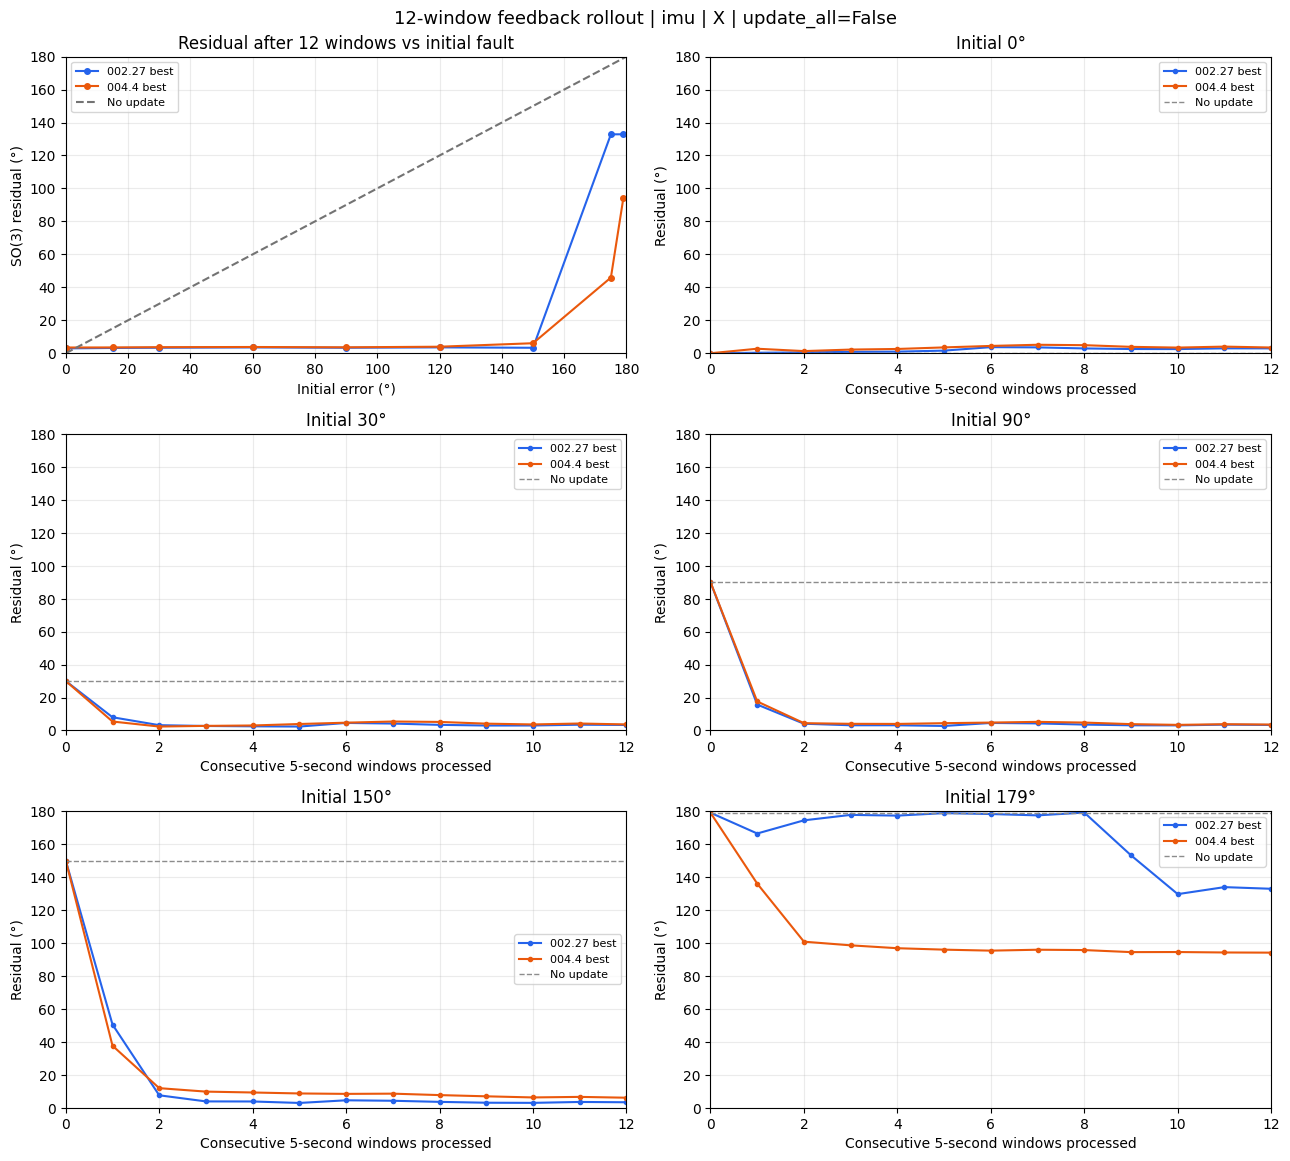

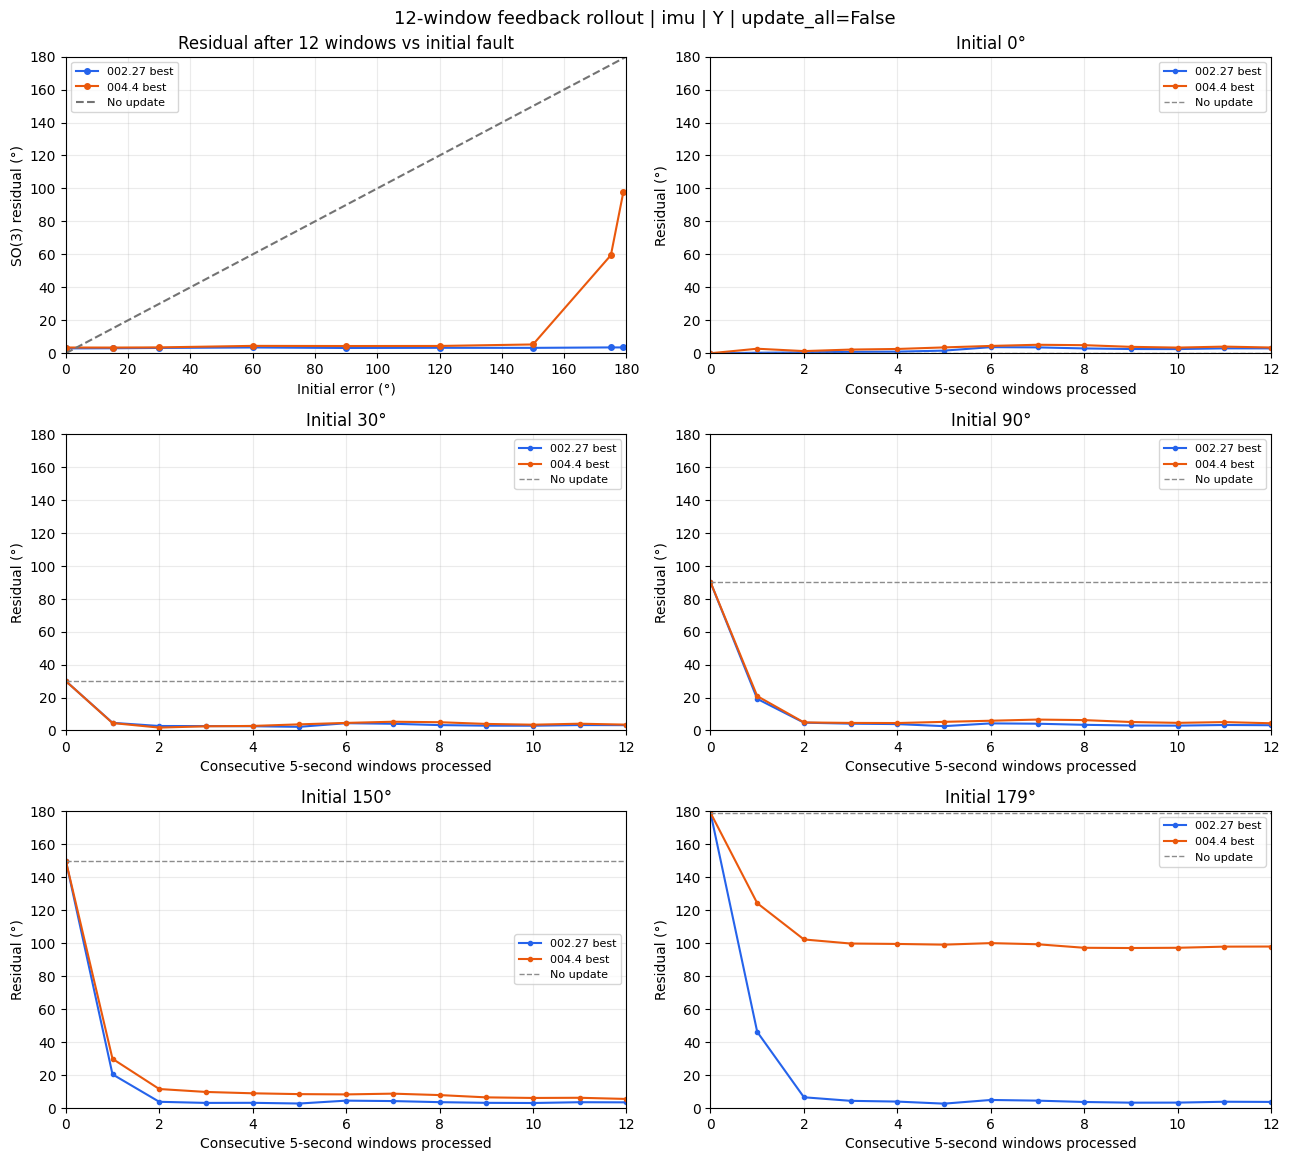

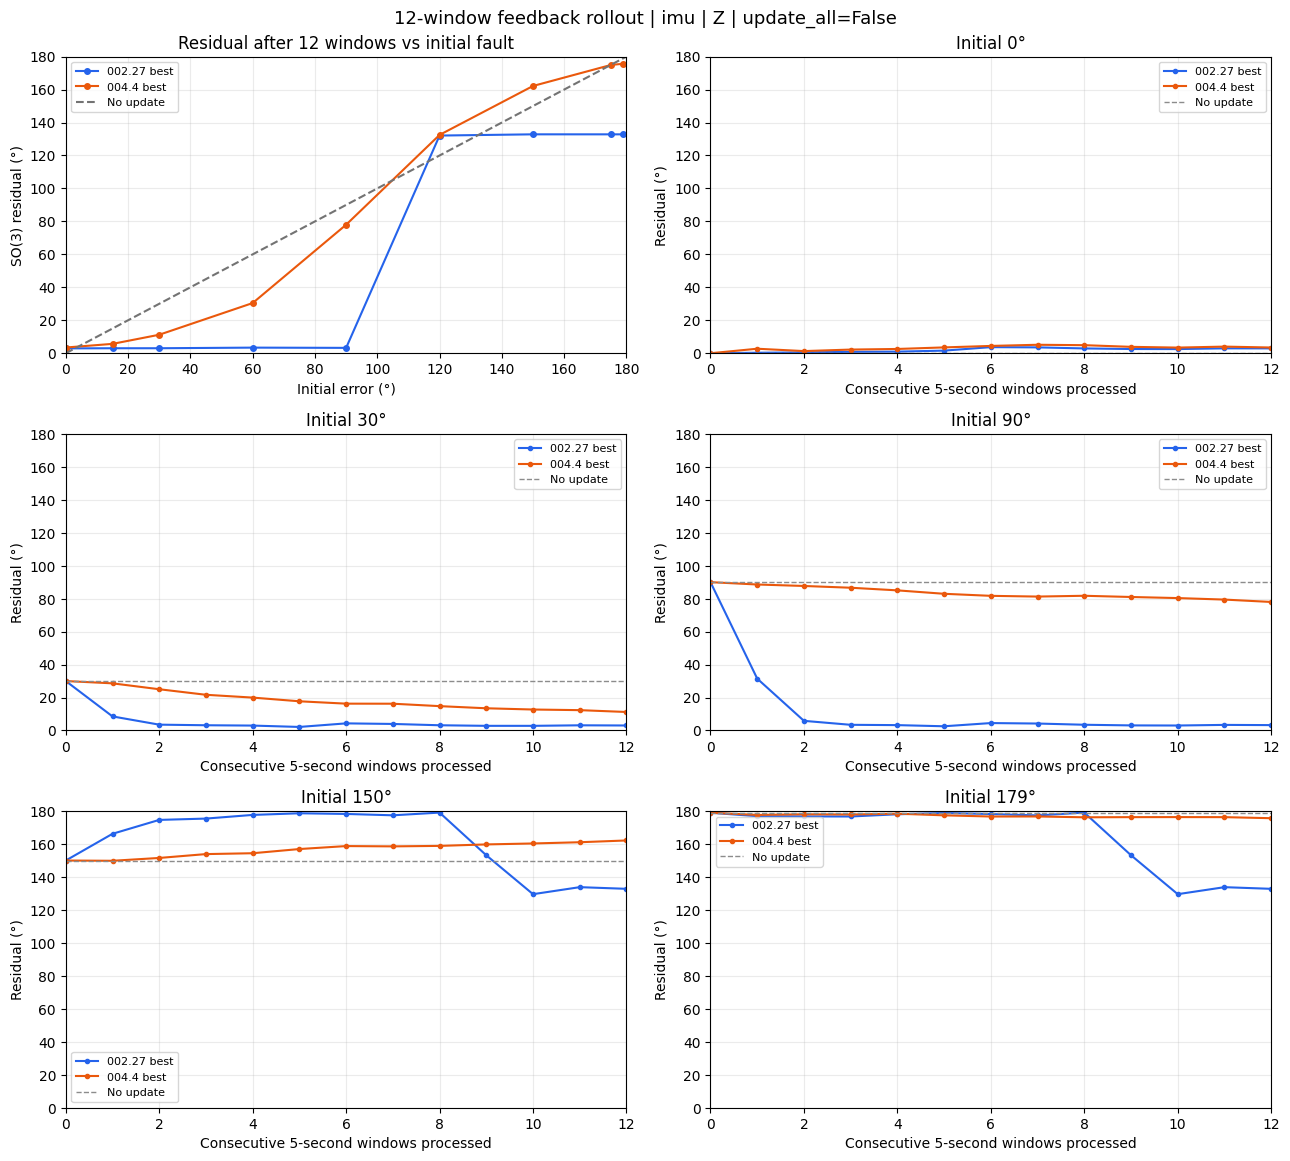

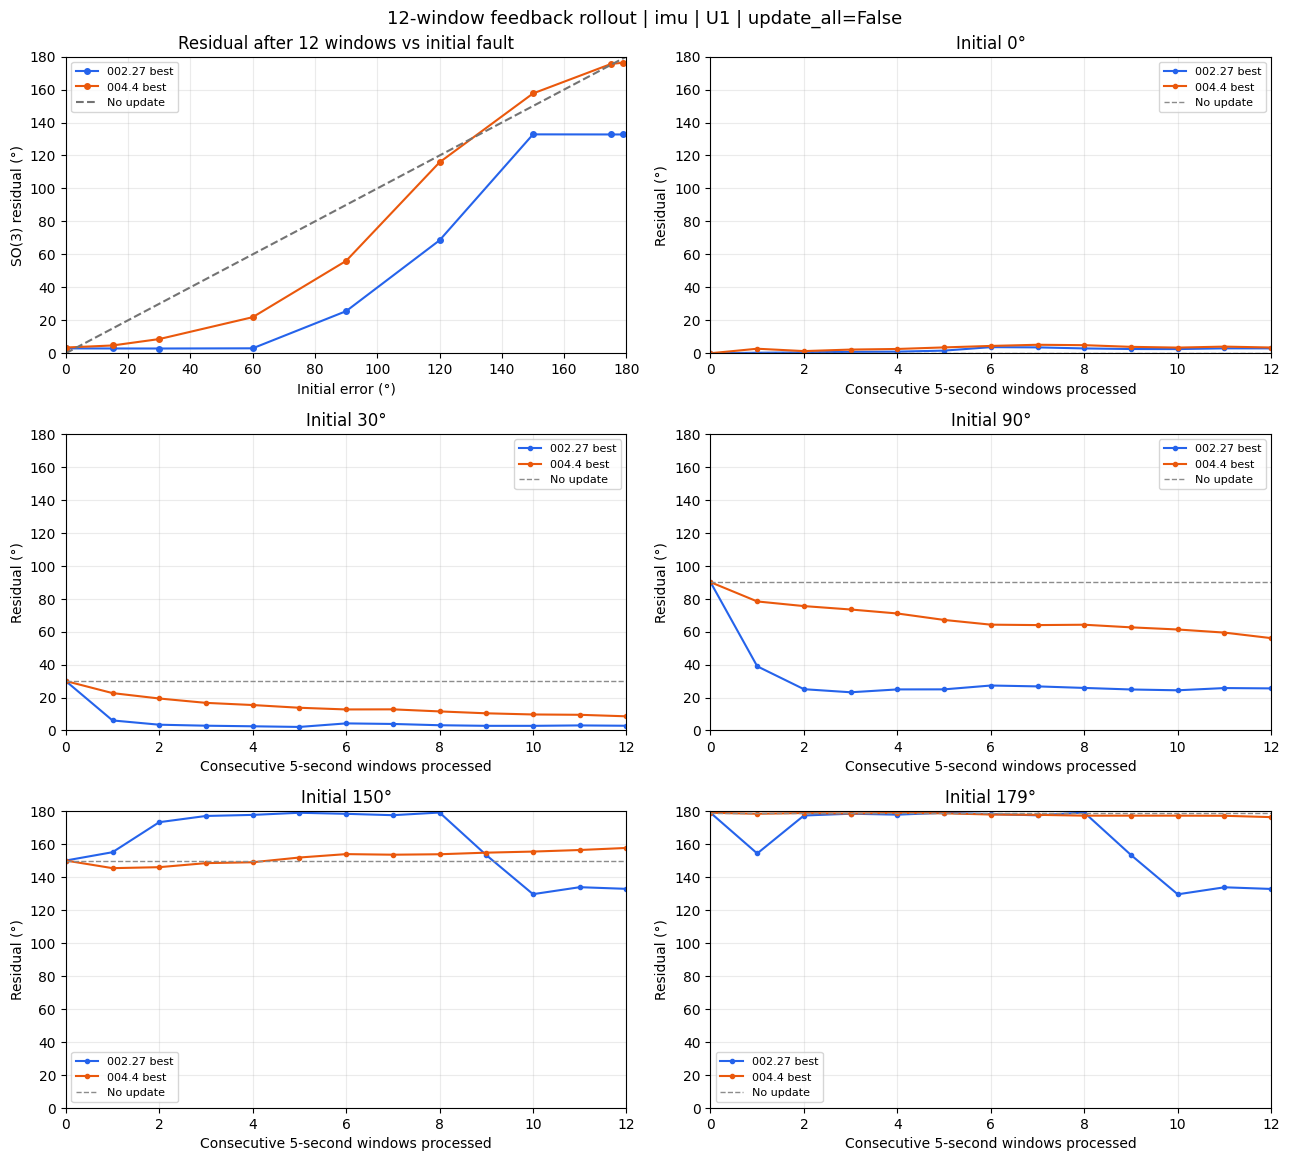

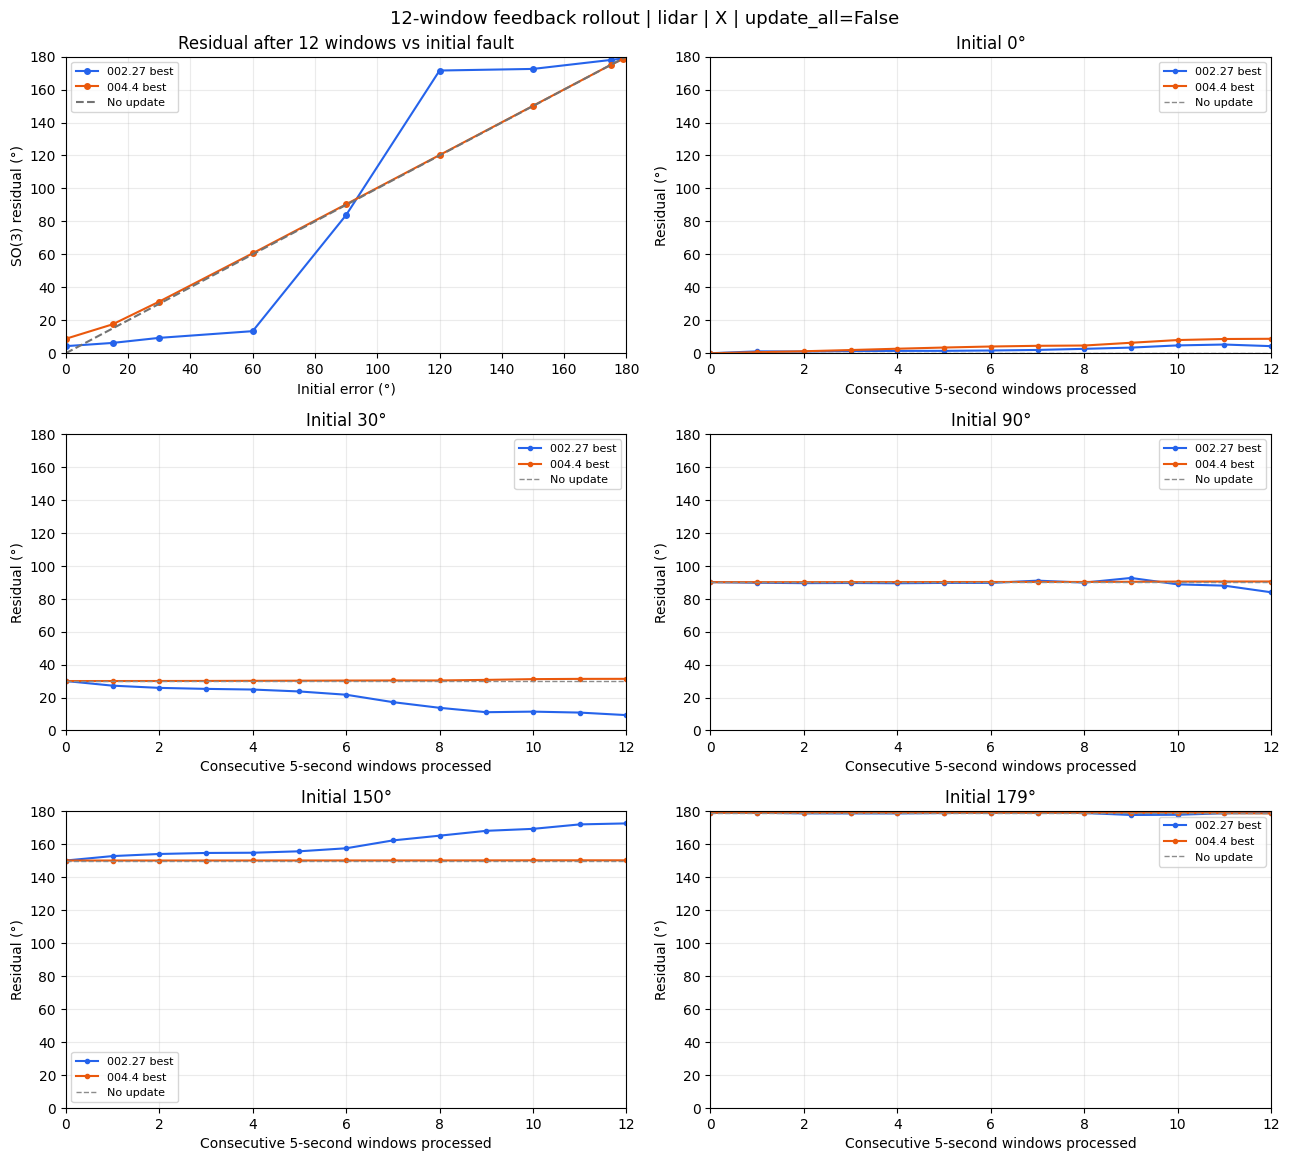

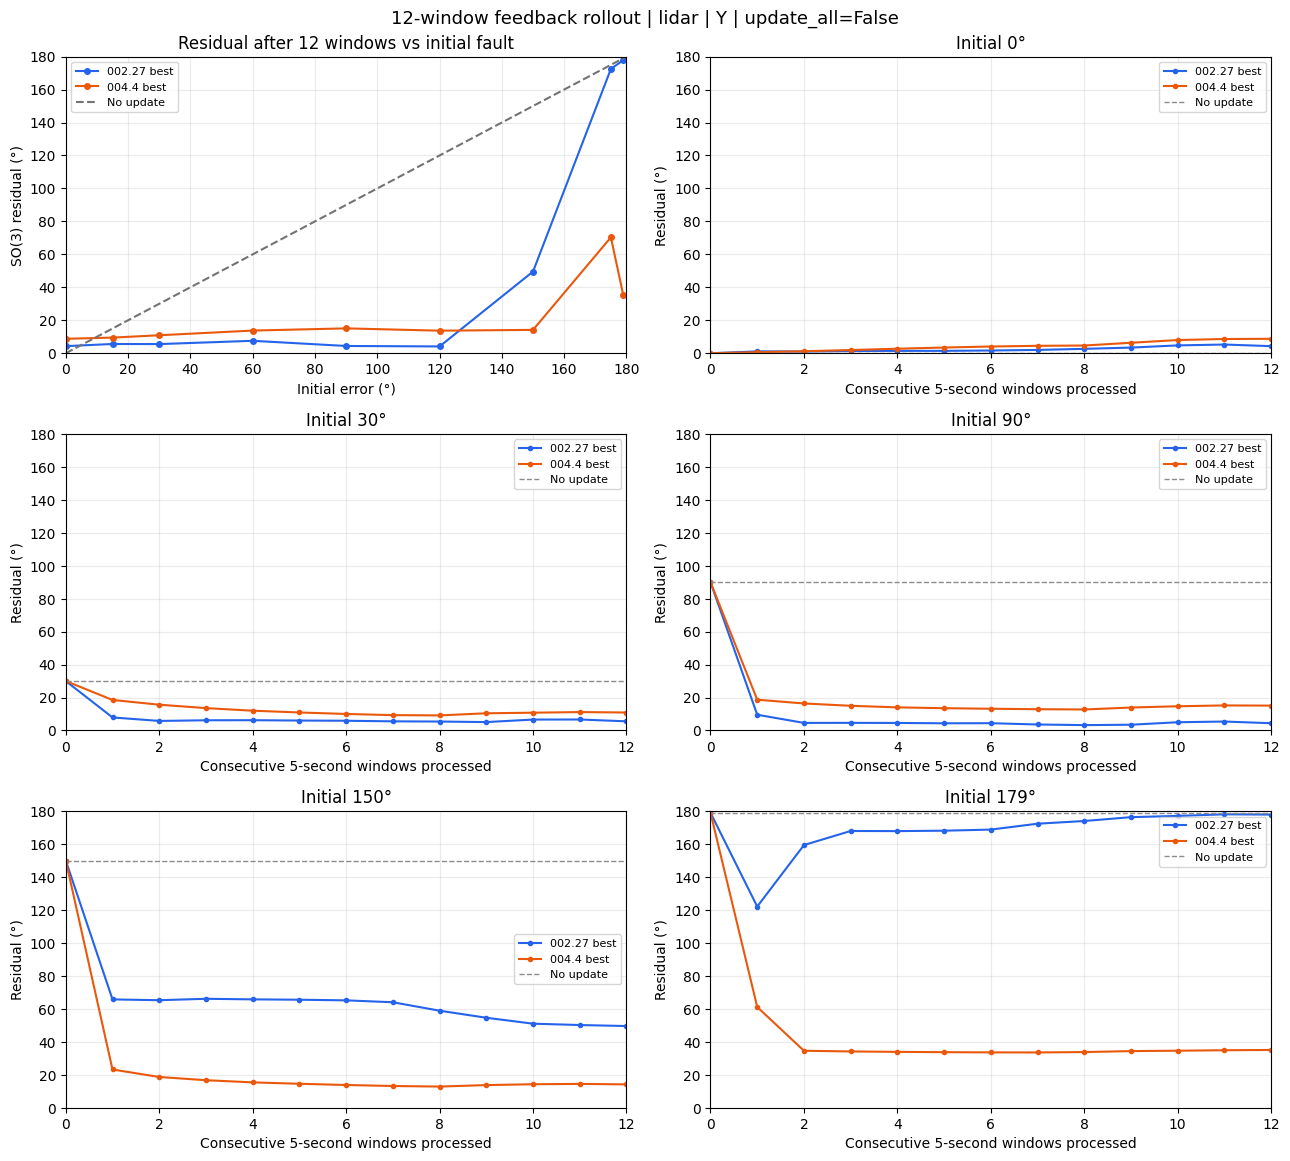

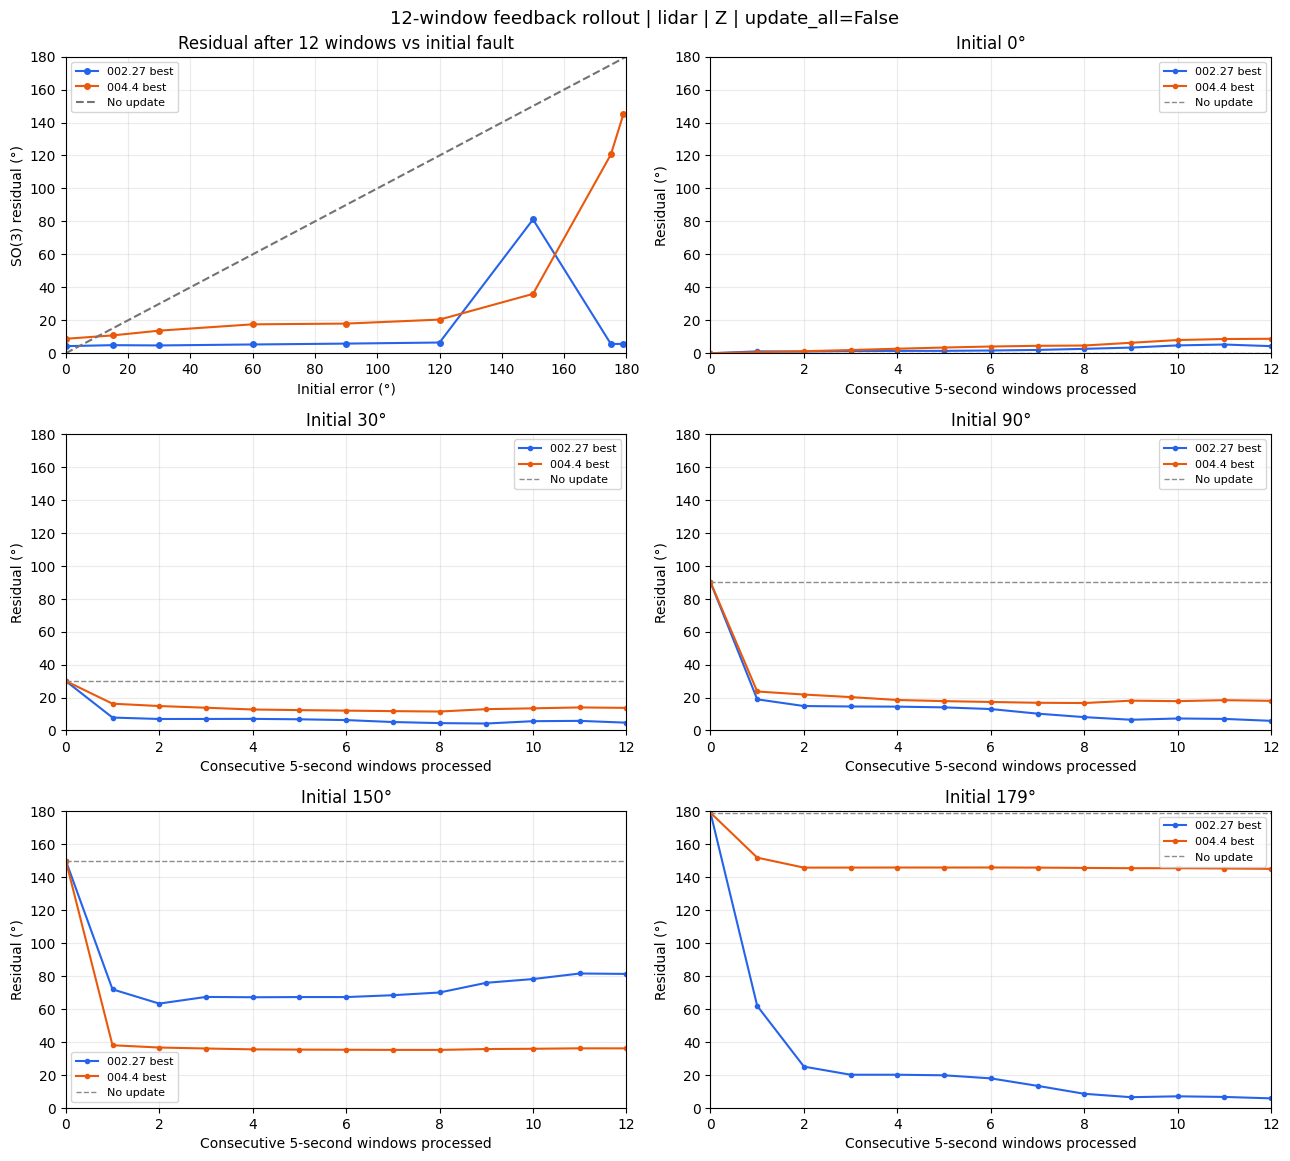

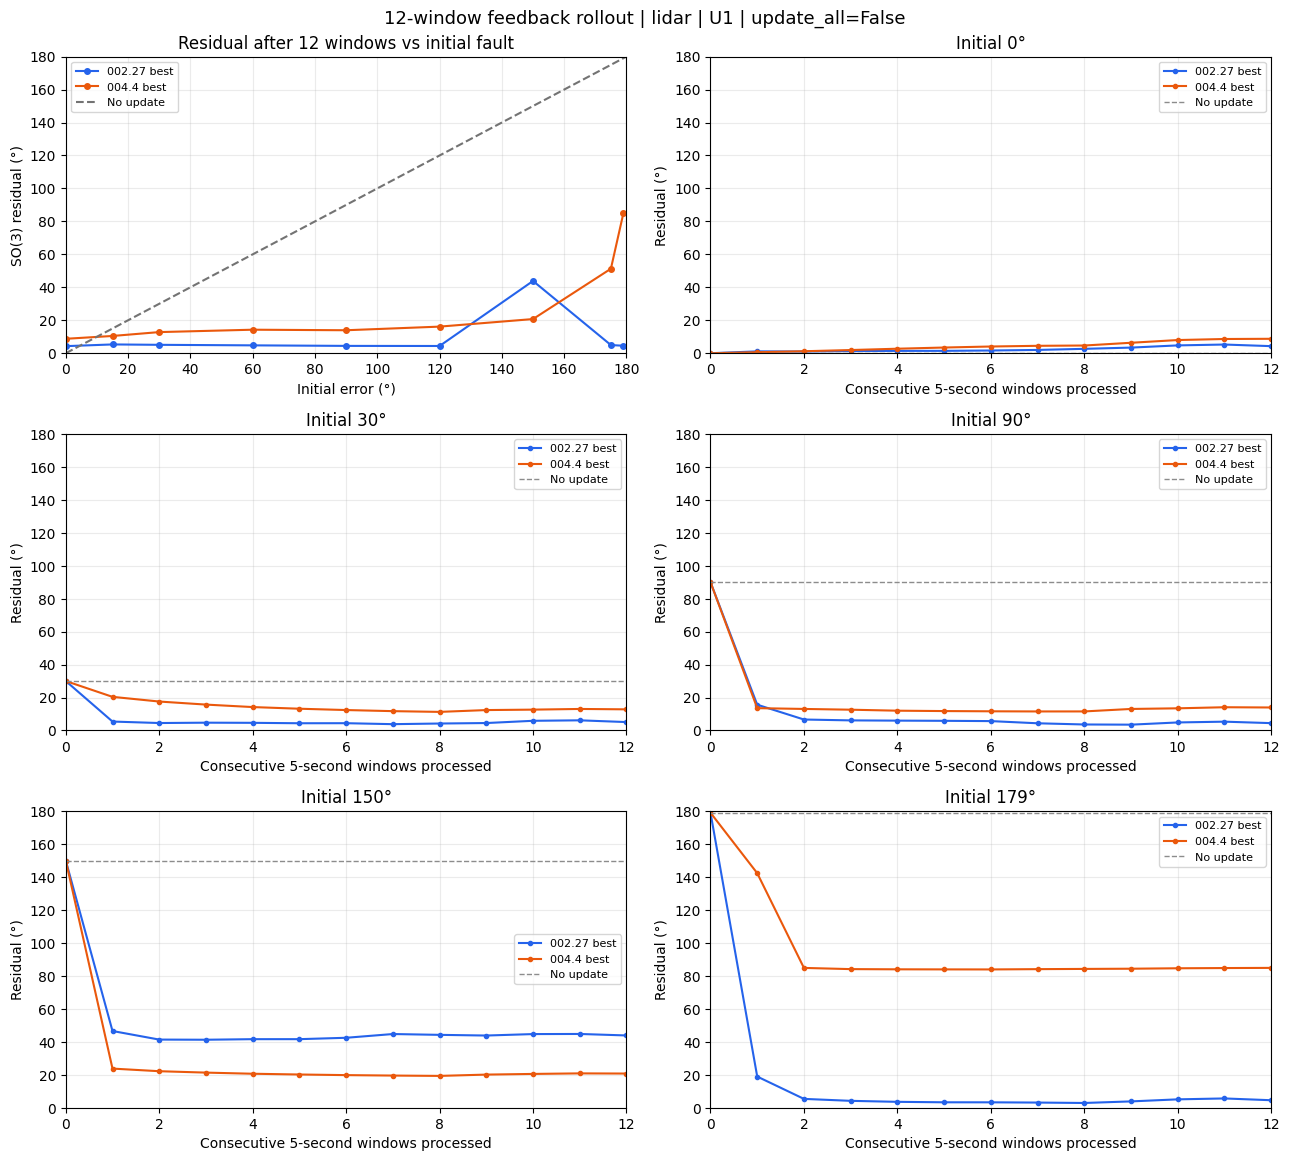

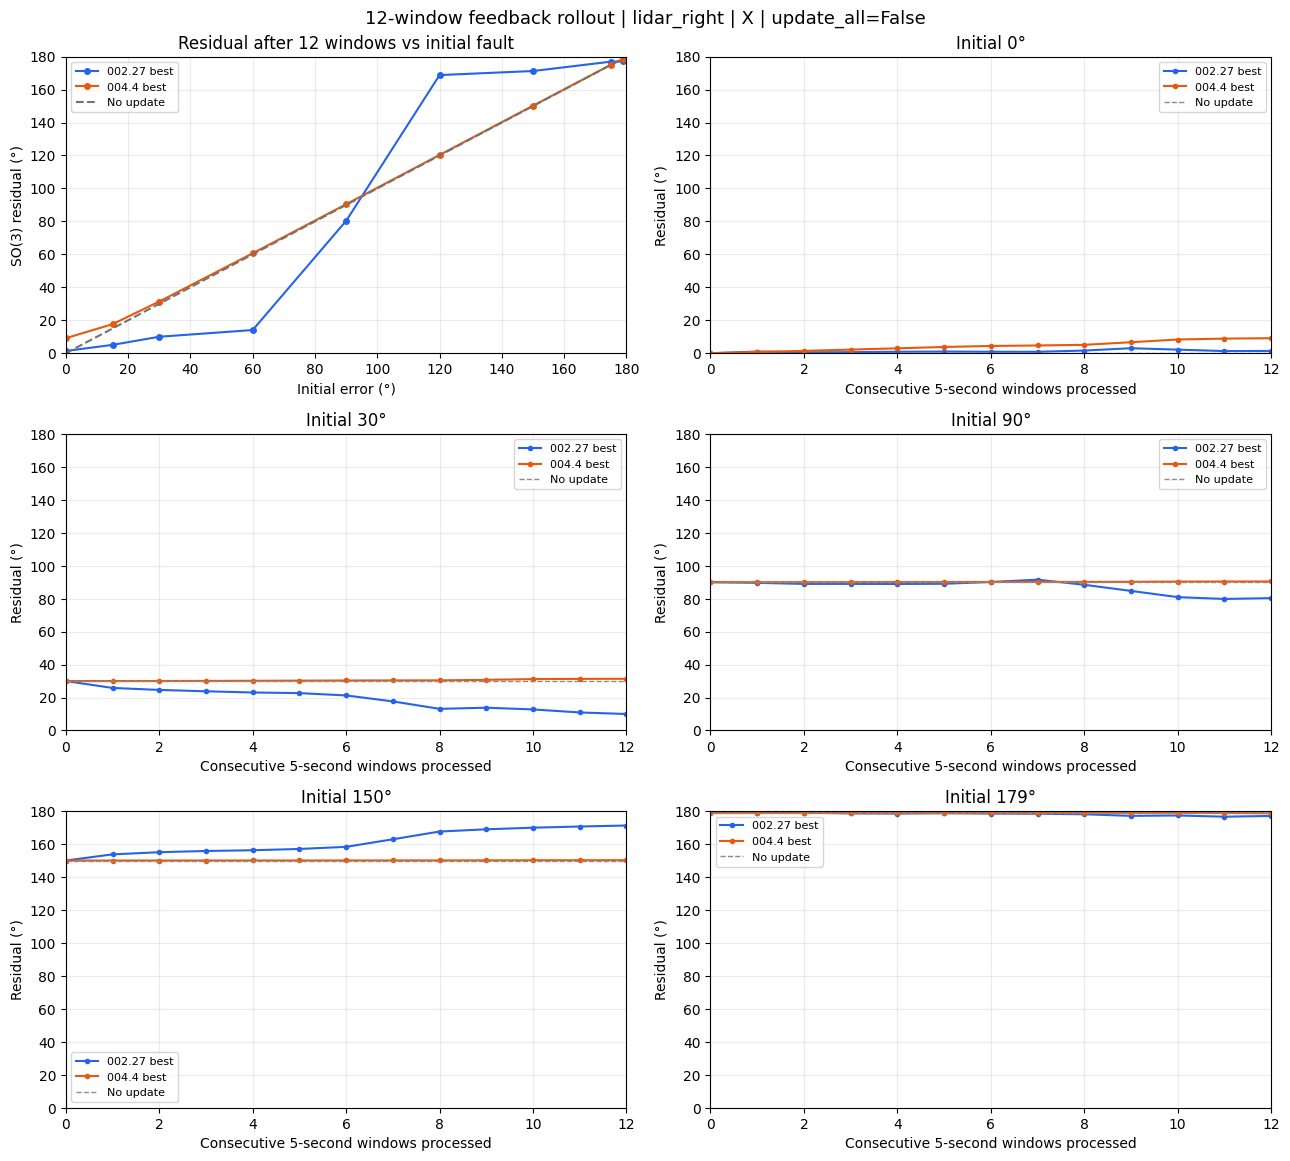

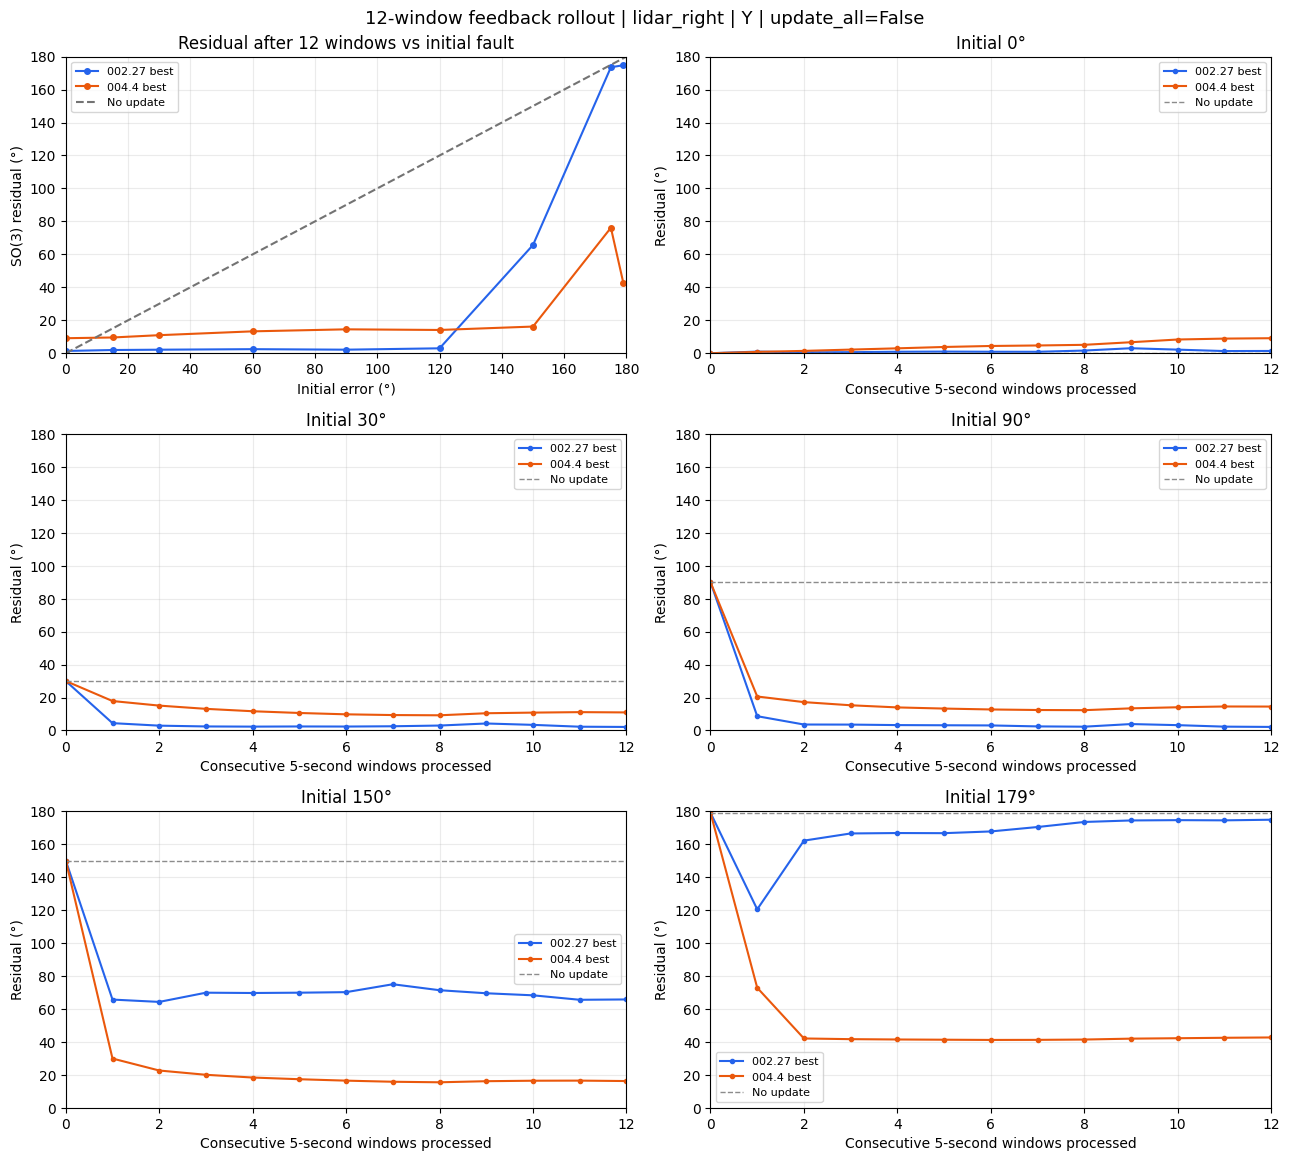

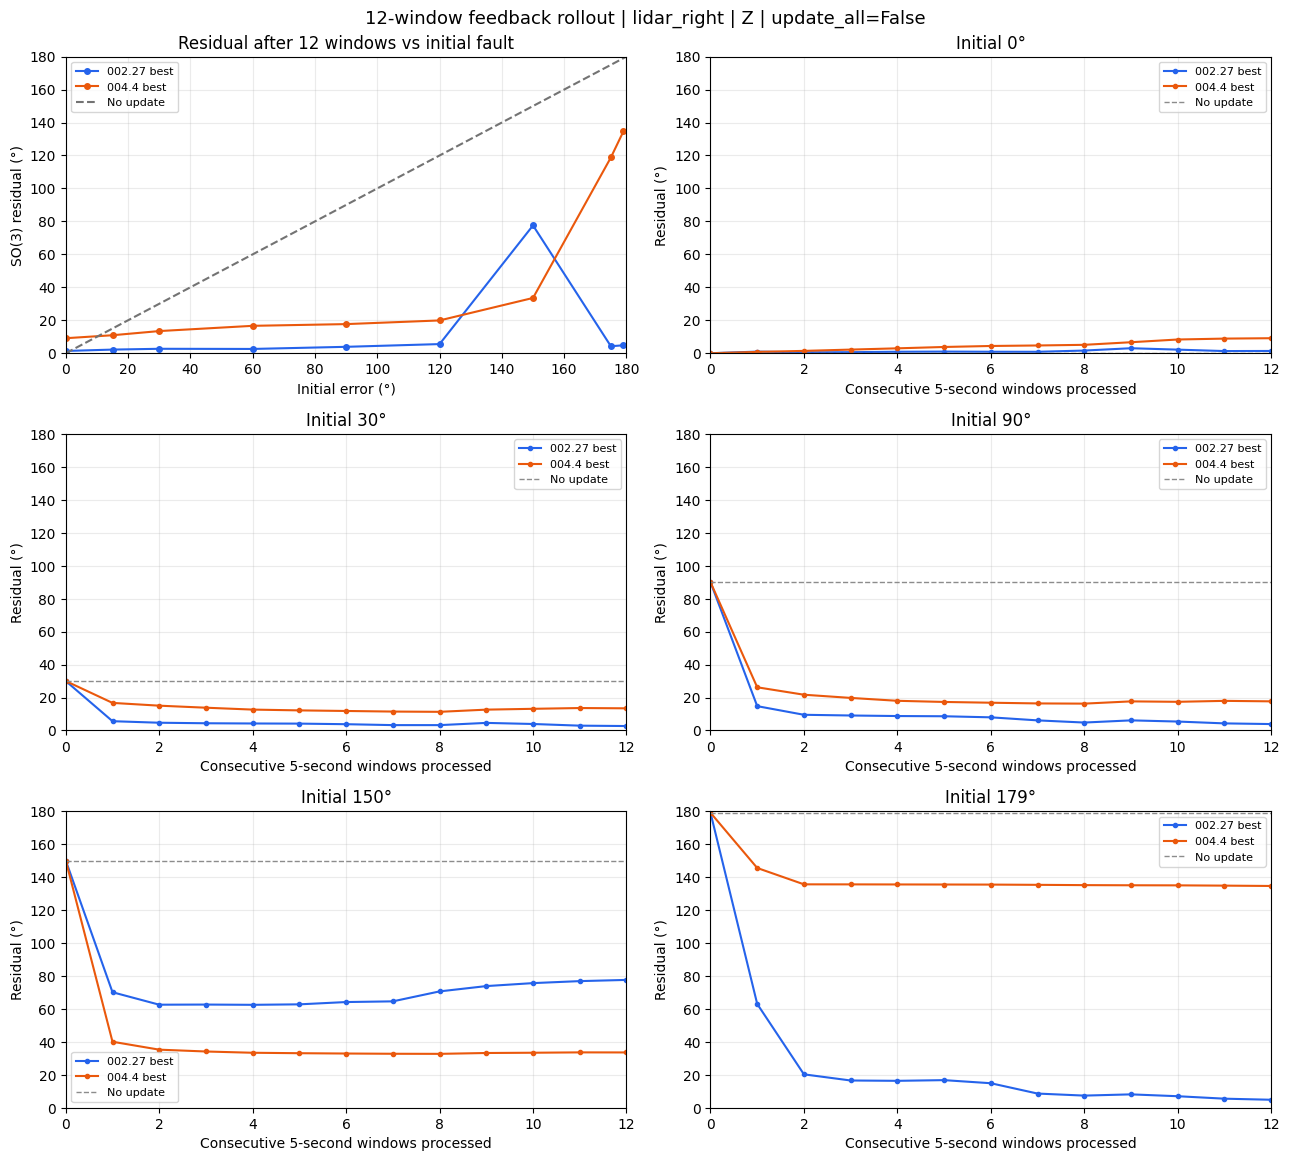

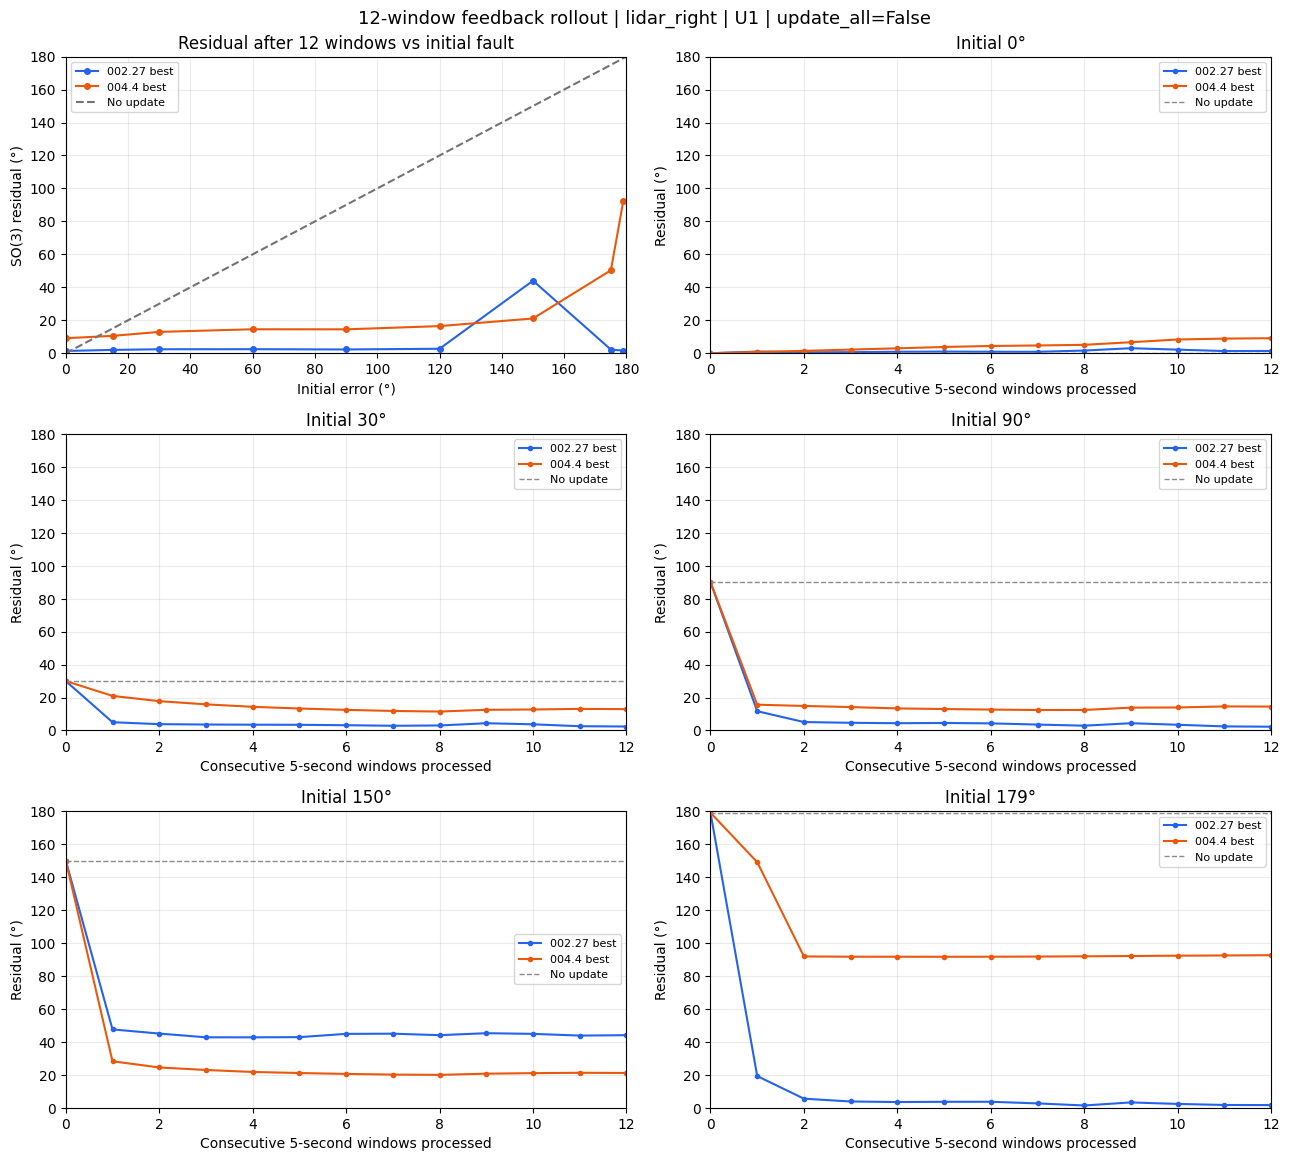

In [10]:
for sensor in FAULT_KEYS:
    for axis_name in AXIS_NAMES:
        fig,axs=plt.subplots(3,2,figsize=(13.0,11.8))
        final_ax=axs[0,0]
        for model_name in MODEL_ORDER:
            curve=rollout_summary[(rollout_summary.model==model_name)&(rollout_summary.sensor==sensor)&(rollout_summary.axis==axis_name)&(rollout_summary.step==ROLLOUT_NUM_WINDOWS)].sort_values('angle_deg')
            final_ax.plot(curve.angle_deg,curve.mean_residual_deg,'-o',label=model_name,color=COLORS[model_name],markersize=4)
        final_ax.plot([0,180],[0,180],'--',color='0.45',label='No update')
        final_ax.set(title='Residual after 12 windows vs initial fault',xlabel='Initial error (°)',ylabel='SO(3) residual (°)',xlim=(0,180),ylim=(0,180))
        final_ax.grid(alpha=.25)
        final_ax.legend(fontsize=8)
        for ax,angle in zip([axs[0,1],axs[1,0],axs[1,1],axs[2,0],axs[2,1]],ROLLOUT_TRACE_ANGLES):
            for model_name in MODEL_ORDER:
                curve=rollout_summary[(rollout_summary.model==model_name)&(rollout_summary.sensor==sensor)&(rollout_summary.axis==axis_name)&(rollout_summary.angle_deg==angle)].sort_values('step')
                ax.plot(curve.step,curve.mean_residual_deg,'-o',markersize=3,label=model_name,color=COLORS[model_name])
            ax.axhline(angle,color='0.55',linestyle='--',linewidth=1,label='No update')
            ax.set(title=f'Initial {angle:g}°',xlabel='Consecutive 5-second windows processed',ylabel='Residual (°)',xlim=(0,ROLLOUT_NUM_WINDOWS),ylim=(0,180))
            ax.grid(alpha=.25)
            ax.legend(fontsize=8)
        fig.suptitle(f'12-window feedback rollout | {sensor} | {axis_name} | update_all={ROLLOUT_UPDATE_ALL_KEYS}',fontsize=13)
        finish_figure(fig,f'rollout_{sensor}_{axis_name}.png')

## 11. Matched checkpoint differences and heatmaps

All physical examples, fault axes, perturbation signs and angles are case-matched, with exactly the same input data for both checkpoints. Define `delta = 004.4 residual − 002.27 residual`: **negative means 004.4 is better**. At 0° initial error, the metric measures unwanted corrections (drift).

One-step matched difference: 004.4 best minus 002.27 best; negative means 004.4 best is better


,sensor,axis,angle_deg,cases,mean_delta_deg,median_delta_deg,win_new_pct,win_old_pct
0,imu,U1,0.0,24,1.25,0.75,16.67,83.33
2,imu,U1,30.0,48,14.03,15.84,4.17,95.83
4,imu,U1,90.0,48,46.67,54.84,6.25,93.75
6,imu,U1,150.0,48,-3.08,-10.21,62.50,37.50
8,imu,U1,179.0,48,18.09,15.49,4.17,95.83
9,imu,X,0.0,24,1.25,0.75,16.67,83.33
11,imu,X,30.0,48,1.15,1.61,35.42,64.58
13,imu,X,90.0,48,6.51,5.55,10.42,89.58
15,imu,X,150.0,48,-13.64,-7.44,81.25,18.75
17,imu,X,179.0,48,-20.19,-16.28,83.33,16.67


Final 12-window matched difference:


,sensor,axis,angle_deg,cases,mean_delta_deg,median_delta_deg,win_new_pct,win_old_pct
0,imu,U1,0.0,4,0.53,1.17,25.0,75.0
2,imu,U1,30.0,8,5.73,5.11,0.0,100.0
4,imu,U1,90.0,8,30.50,52.03,12.5,87.5
6,imu,U1,150.0,8,24.83,-11.37,75.0,25.0
8,imu,U1,179.0,8,43.59,2.49,12.5,87.5
9,imu,X,0.0,4,0.53,1.17,25.0,75.0
11,imu,X,30.0,8,0.33,1.06,37.5,62.5
13,imu,X,90.0,8,0.27,0.59,37.5,62.5
15,imu,X,150.0,8,2.76,1.30,12.5,87.5
17,imu,X,179.0,8,-38.75,-48.48,62.5,37.5


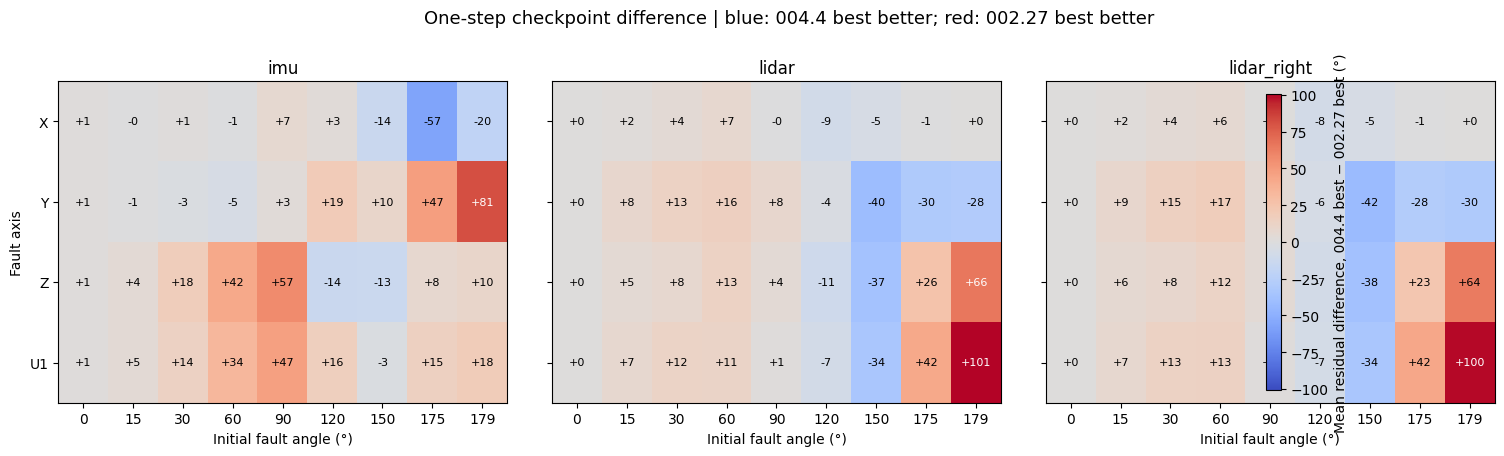

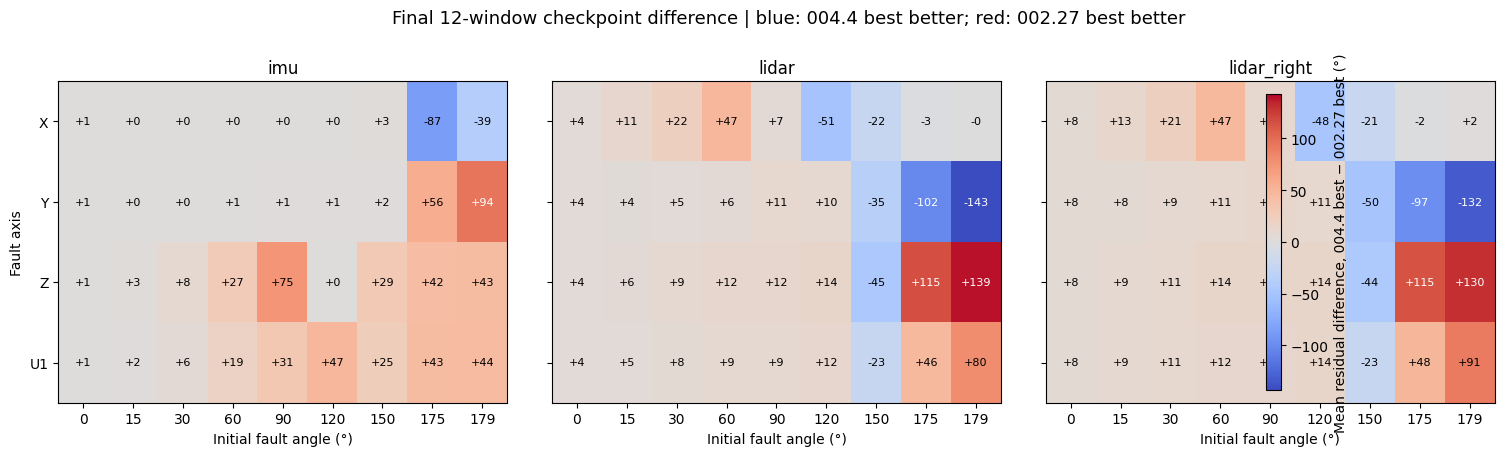

In [11]:
def matched_difference(df, case_columns):
    """Subtract residuals for precisely matched physical and injected-fault cases."""
    if df.duplicated(['model', *case_columns]).any():
        raise AssertionError('Duplicate rows for model and matched-case identity')
    pivot = df.pivot(index=case_columns, columns='model', values='residual_deg')
    if pivot.isna().any().any():
        raise AssertionError('Both models must be present on every case')
    diff = pivot.reset_index()
    diff[DELTA_COLUMN] = diff[NEW_MODEL_NAME] - diff[OLD_MODEL_NAME]
    diff['winner'] = np.where(diff[DELTA_COLUMN] < -1e-3, NEW_MODEL_NAME,
                              np.where(diff[DELTA_COLUMN] > 1e-3, OLD_MODEL_NAME, 'tie'))
    return diff


one_step_paired = matched_difference(one_step_df, ['sequence', 'physical_index', 'sensor', 'axis', 'angle_deg', 'sign'])
rollout_paired = matched_difference(rollout_df, ['sequence', 'start_index', 'sensor', 'axis', 'angle_deg', 'sign', 'step'])
one_step_paired.to_csv(OUTPUT_DIR / 'one_step_paired_differences.csv', index=False)
rollout_paired.to_csv(OUTPUT_DIR / 'rollout_paired_differences.csv', index=False)


def summarize_paired(df):
    return df.groupby(['sensor', 'axis', 'angle_deg'], as_index=False).agg(
        cases=(DELTA_COLUMN, 'size'), mean_delta_deg=(DELTA_COLUMN, 'mean'), median_delta_deg=(DELTA_COLUMN, 'median'),
        win_new_pct=('winner', lambda w: 100 * np.mean(w == NEW_MODEL_NAME)),
        win_old_pct=('winner', lambda w: 100 * np.mean(w == OLD_MODEL_NAME)),
    )


one_step_delta_summary = summarize_paired(one_step_paired)
final_rollout_paired = rollout_paired[rollout_paired.step == ROLLOUT_NUM_WINDOWS]
rollout_delta_summary = summarize_paired(final_rollout_paired)
one_step_delta_summary.to_csv(OUTPUT_DIR / 'one_step_paired_summary.csv', index=False)
rollout_delta_summary.to_csv(OUTPUT_DIR / 'rollout_final_paired_summary.csv', index=False)

print(f'One-step matched difference: {NEW_MODEL_NAME} minus {OLD_MODEL_NAME}; negative means {NEW_MODEL_NAME} is better')
display(one_step_delta_summary[one_step_delta_summary.angle_deg.isin((0., 30., 90., 150., 179.))].round(2))
print('Final 12-window matched difference:')
display(rollout_delta_summary[rollout_delta_summary.angle_deg.isin((0., 30., 90., 150., 179.))].round(2))


def plot_delta_heatmaps(summary, heading, filename):
    fig, axs = plt.subplots(1, 3, figsize=(16.8, 4.8), sharex=True, sharey=True)
    vlim = max(5.0, float(np.nanmax(np.abs(summary.mean_delta_deg))))
    for ax, sensor in zip(axs, FAULT_KEYS):
        data = summary[summary.sensor == sensor].pivot(index='axis', columns='angle_deg', values='mean_delta_deg').reindex(index=AXIS_NAMES, columns=ANGLES_DEG)
        image = ax.imshow(data.to_numpy(), cmap='coolwarm', vmin=-vlim, vmax=vlim, aspect='auto')
        ax.set(title=sensor, xticks=range(len(ANGLES_DEG)), xticklabels=[f'{a:g}' for a in ANGLES_DEG],
               yticks=range(len(AXIS_NAMES)), yticklabels=AXIS_NAMES)
        ax.set_xlabel('Initial fault angle (°)')
        if ax is axs[0]:
            ax.set_ylabel('Fault axis')
        for row in range(len(AXIS_NAMES)):
            for col in range(len(ANGLES_DEG)):
                value = data.iat[row, col]
                if np.isfinite(value):
                    ax.text(col, row, f'{value:+.0f}', ha='center', va='center', fontsize=8,
                            color='black' if abs(value) < vlim * .65 else 'white')
    fig.colorbar(image, ax=axs.ravel().tolist(), label=f'Mean residual difference, {NEW_MODEL_NAME} − {OLD_MODEL_NAME} (°)', shrink=.80, pad=.015)
    fig.suptitle(heading + f' | blue: {NEW_MODEL_NAME} better; red: {OLD_MODEL_NAME} better', fontsize=13)
    fig.subplots_adjust(left=.065, right=.92, top=.83, bottom=.16, wspace=.10)
    if SAVE_PLOTS:
        fig.savefig(OUTPUT_DIR / filename, dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


plot_delta_heatmaps(one_step_delta_summary, 'One-step checkpoint difference', 'one_step_checkpoint_delta_heatmap.png')
plot_delta_heatmaps(rollout_delta_summary, 'Final 12-window checkpoint difference', 'rollout_checkpoint_delta_heatmap.png')

## 12. Per-case checkpoint agreement and disagreement

Each point is one fully matched physical case. Points **below** the diagonal favor `004.4`; points **above** favor `002.27`. Plots focus on faults of 90°, 150° and 179° after one update and after all 12 consecutive windows.

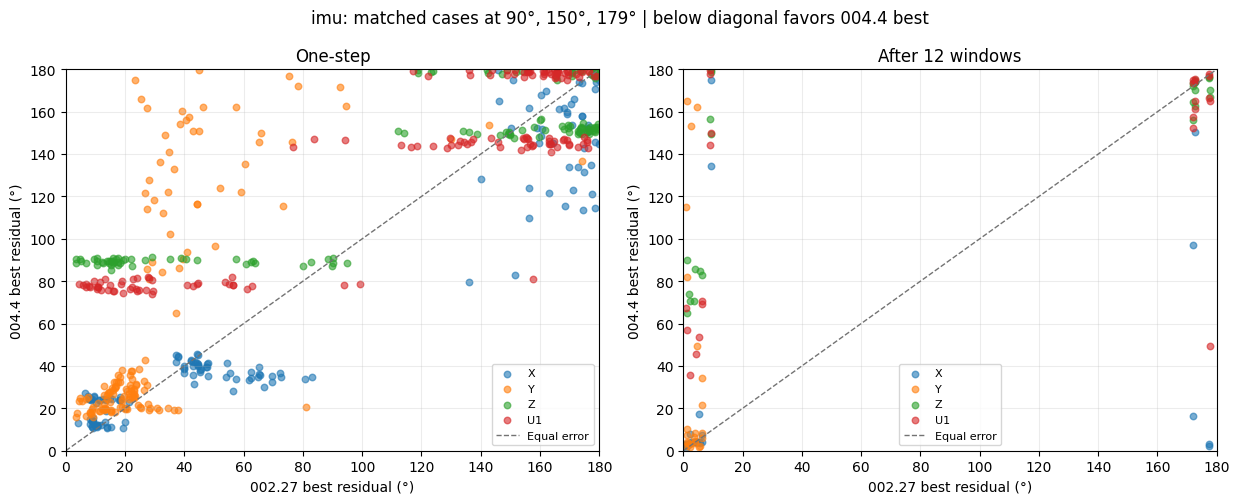

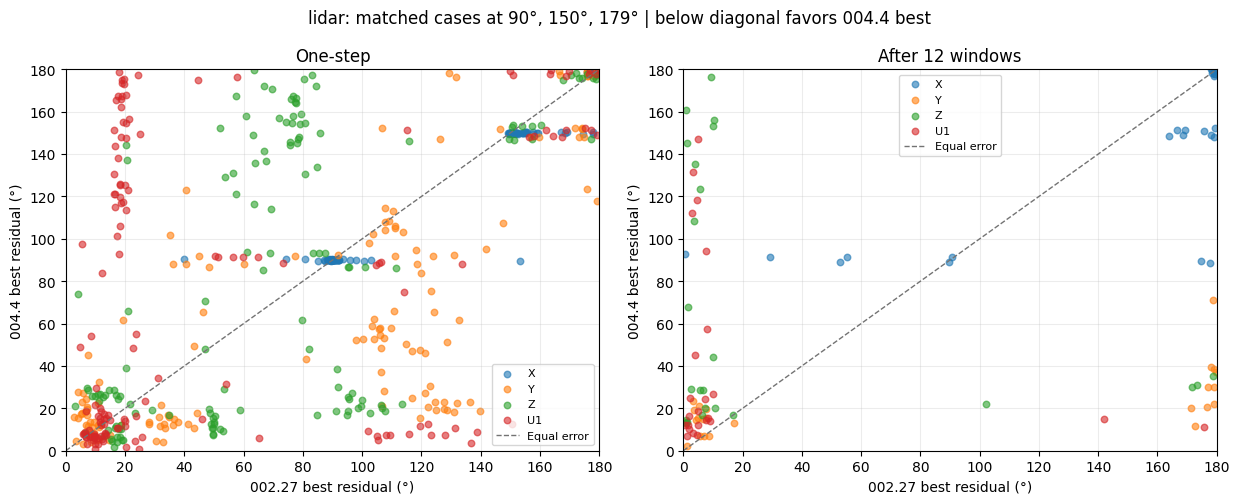

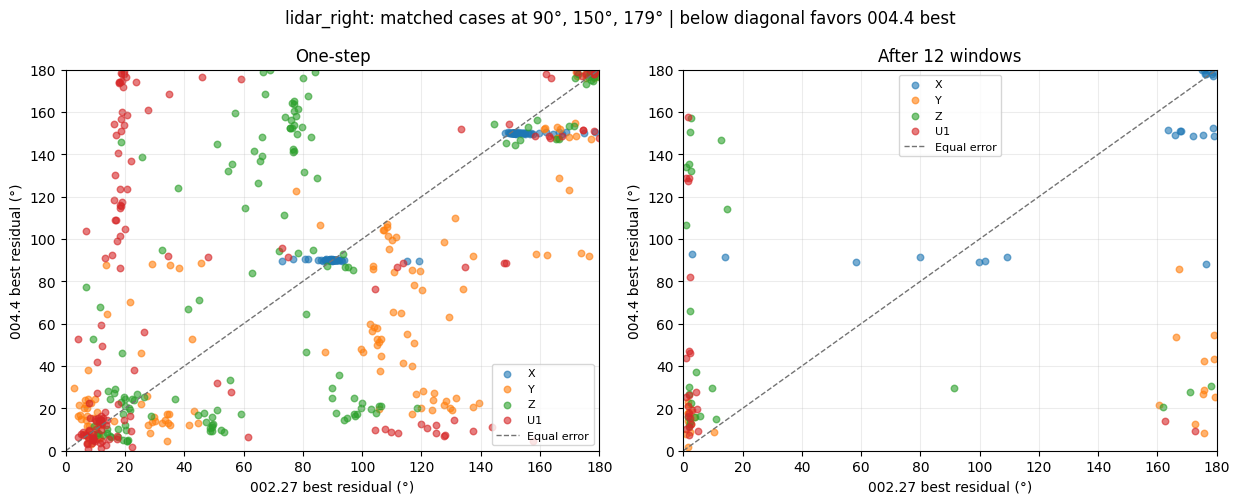

In [12]:
# Every scatter point compares the same sequence/window, sensor, axis, sign and injected angle.
for sensor in FAULT_KEYS:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.1))
    for ax, source, caption in ((axes[0], one_step_paired, 'One-step'),
                                (axes[1], final_rollout_paired, 'After 12 windows')):
        data = source[(source.sensor == sensor) & (source.angle_deg.isin((90., 150., 179.)))]
        for axis_name in AXIS_NAMES:
            points = data[data.axis == axis_name]
            ax.scatter(points[OLD_MODEL_NAME], points[NEW_MODEL_NAME], s=22, alpha=.60, label=axis_name)
        ax.plot([0, 180], [0, 180], '--', color='0.45', linewidth=1, label='Equal error')
        ax.set(title=caption, xlabel=f'{OLD_MODEL_NAME} residual (°)', ylabel=f'{NEW_MODEL_NAME} residual (°)',
               xlim=(0, 180), ylim=(0, 180))
        ax.grid(alpha=.23)
        ax.legend(fontsize=8)
    fig.suptitle(f'{sensor}: matched cases at 90°, 150°, 179° | below diagonal favors {NEW_MODEL_NAME}', fontsize=12)
    finish_figure(fig, f'paired_scatter_{sensor}.png')

## 13. Final scorecard: zero-error drift, mean/median/p90 residual and success at 10°

In [13]:
def scorecard_for(df, label):
    nonzero=df[df.angle_deg>0]
    grouped=nonzero.groupby(['model','sensor'],as_index=False).agg(
        n=('residual_deg','size'),mean_initial_deg=('angle_deg','mean'),mean_residual_deg=('residual_deg','mean'),
        median_residual_deg=('residual_deg','median'),p90_residual_deg=('residual_deg',lambda x:np.percentile(x,90)),
        improved_pct=('improved',lambda x:100*x.mean()),success_10deg_pct=('success_10deg',lambda x:100*x.mean()))
    zeros=df[df.angle_deg==0].groupby(['model','sensor'],as_index=False).agg(zero_drift_deg=('residual_deg','mean'))
    grouped=grouped.merge(zeros,on=['model','sensor'],how='left')
    grouped.insert(0,'evaluation',label)
    return grouped

summary_one=scorecard_for(one_step_df,'one_step')
summary_final=scorecard_for(rollout_df[rollout_df.step==ROLLOUT_NUM_WINDOWS],'after_12_windows')
scorecard=pd.concat([summary_one,summary_final],ignore_index=True)
scorecard.to_csv(OUTPUT_DIR/'checkpoint_scorecard.csv',index=False)
display(scorecard.round(2))

print('\nSelected 30°/90°/150°/179° final rollout residuals by sensor and axis:')
final_table=rollout_summary[(rollout_summary.step==ROLLOUT_NUM_WINDOWS)&(rollout_summary.angle_deg.isin((30.,90.,150.,179.)))]
display(final_table.pivot_table(index=['sensor','axis','angle_deg'],columns='model',values='mean_residual_deg').round(1))

config_summary={
    'checkpoints':{key:str(val) for key,val in CHECKPOINTS.items()},'split':EVAL_SPLIT,
    'new_checkpoint_filename':NEW_CHECKPOINT_FILENAME,
    'model_architectures':{key:{arch_key:(list(arch_value) if isinstance(arch_value,tuple) else arch_value) for arch_key,arch_value in arch.items() if arch_key!='model_class'} for key,arch in MODEL_ARCHITECTURES.items()},
    'sequences':EVAL_SEQUENCES,'angles_deg':ANGLES_DEG,'axis_names':AXIS_NAMES,
    'axis_vectors':{key:val.cpu().numpy().tolist() for key,val in AXES.items()},
    'one_step_windows_per_sequence':ONE_STEP_WINDOWS_PER_SEQUENCE,
    'rollout_windows':ROLLOUT_NUM_WINDOWS,'rollout_starts_per_sequence':ROLLOUT_STARTS_PER_SEQUENCE,
    'rollout_update_all_keys':ROLLOUT_UPDATE_ALL_KEYS,
    'true_rotation_max_deg':TRUE_CALIBRATION_ROTATION_MAX_DEG,'true_time_offset_max_s':TRUE_CALIBRATION_TAU_MAX_S,
    'one_step_seed':ONE_STEP_PHYSICAL_SEED,'rollout_seed':ROLLOUT_PHYSICAL_SEED,
}
(OUTPUT_DIR/'evaluation_config.json').write_text(json.dumps(config_summary,indent=2),encoding='utf-8')
print('\nSaved all results under:',OUTPUT_DIR)
print('No optimizer was constructed and neither checkpoint was modified.')

,evaluation,model,sensor,n,mean_initial_deg,mean_residual_deg,median_residual_deg,p90_residual_deg,improved_pct,success_10deg_pct,zero_drift_deg
0,one_step,002.27 best,imu,1536,102.38,60.04,21.35,170.46,88.35,31.58,0.59
1,one_step,002.27 best,lidar,1536,102.38,60.41,28.12,170.63,83.07,22.53,1.24
2,one_step,002.27 best,lidar_right,1536,102.38,60.68,27.09,172.77,82.16,23.76,1.26
3,one_step,004.4 best,imu,1536,102.38,70.24,44.10,174.62,87.17,15.95,1.84
4,one_step,004.4 best,lidar,1536,102.38,65.06,30.06,173.46,77.86,11.65,1.53
5,one_step,004.4 best,lidar_right,1536,102.38,65.26,30.13,174.09,78.58,12.43,1.70
6,after_12_windows,002.27 best,imu,256,102.38,42.40,4.88,172.58,89.06,76.95,2.94
7,after_12_windows,002.27 best,lidar,256,102.38,44.94,7.42,178.27,82.42,66.80,4.30
8,after_12_windows,002.27 best,lidar_right,256,102.38,43.51,2.92,175.85,83.98,69.53,1.38
9,after_12_windows,004.4 best,imu,256,102.38,57.33,10.45,174.04,85.94,49.22,3.47



Selected 30°/90°/150°/179° final rollout residuals by sensor and axis:


model                       002.27 best  004.4 best
sensor      axis angle_deg                         
imu         U1   30.0               2.9         8.6
                 90.0              25.5        56.0
                 150.0            132.8       157.6
                 179.0            132.8       176.3
            X    30.0               3.3         3.7
                 90.0               3.3         3.6
                 150.0              3.3         6.1
                 179.0            132.9        94.1
            Y    30.0               3.2         3.5
                 90.0               3.2         4.4
                 150.0              3.3         5.3
                 179.0              3.5        97.8
            Z    30.0               3.0        11.2
                 90.0               3.3        78.0
                 150.0            132.8       162.2
                 179.0            132.8       175.7
lidar       U1   30.0               5.1        12.8
                 90.0               4.5        13.9
                 150.0             43.9        20.7
                 179.0              4.5        84.9
            X    30.0               9.3        31.3
                 90.0              83.9        90.4
                 150.0            172.5       150.1
                 179.0            178.9       178.6
            Y    30.0               5.5        10.9
                 90.0               4.4        15.1
                 150.0             49.6        14.2
                 179.0            177.9        35.1
            Z    30.0               4.7        13.7
                 90.0               5.8        18.0
                 150.0             81.2        36.0
                 179.0              5.7       144.9
lidar_right U1   30.0               2.4        12.9
                 90.0               2.3        14.5
                 150.0             44.0        21.1
                 179.0              1.6        92.5
            X    30.0              10.0        31.4
                 90.0              80.3        90.4
                 150.0            171.2       150.2
                 179.0            177.1       178.7
            Y    30.0               2.1        11.0
                 90.0               2.2        14.5
                 150.0             65.7        16.2
                 179.0            174.8        42.6
            Z    30.0               2.7        13.4
                 90.0               3.9        17.7
                 150.0             77.6        33.5
                 179.0              4.8       134.6


Saved all results under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/checkpoint_comparison_00227_best_vs_0044_best/validation
No optimizer was constructed and neither checkpoint was modified.


# Appendix A

In [14]:
# Appendix A: one-step, all-head cross-sensor diagnostic
# Run after notebook section 5; depends on those variables.

# %%
# A1. Independent diagnostic settings and prediction-object schema inspection.
# Prerequisites: notebook sections 1-5 (up to both loaded models / smoke_compare_interfaces).
from dataclasses import fields as dataclass_fields, is_dataclass

APPENDIX_WINDOWS_PER_SEQUENCE = 4
APPENDIX_PHYSICAL_BATCH_SIZE = 2
APPENDIX_FAULT_AXES = ('U1',)  # Add 'X', 'Y', 'Z' for an exhaustive axis study.
APPENDIX_FAULT_ANGLES_DEG = (0., 10., 30., 90., 150., 179.)
APPENDIX_FAULT_SIGNS = (-1, 1)  # Zero angle is evaluated only once.
APPENDIX_SAVE_RESULTS = True
APPENDIX_SHOW_FIGURES = True
APPENDIX_OUTPUT_DIR = OUTPUT_DIR / 'appendix_all_head_one_step'
APPENDIX_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def appendix_public_fields(obj):
    """Find actual public data fields without assuming identical head types for the two models."""
    if isinstance(obj, dict):
        return dict(obj)
    if is_dataclass(obj) and not isinstance(obj, type):
        return {field.name: getattr(obj, field.name) for field in dataclass_fields(obj)}
    if hasattr(obj, '_fields'):
        return {key: getattr(obj, key) for key in obj._fields}
    if hasattr(obj, '__dict__'):
        return {key: value for key, value in vars(obj).items() if not key.startswith('_') and not callable(value)}
    return {key: value for key in dir(obj) if not key.startswith('_') and not callable(getattr(obj, key))}


def appendix_field_description(value):
    if isinstance(value, torch.Tensor):
        return f'tensor {tuple(value.shape)}, dtype={value.dtype}, device={value.device}'
    if isinstance(value, dict):
        return f'mapping keys={tuple(value)}'
    if isinstance(value, (tuple, list)):
        return f'{type(value).__name__} length={len(value)}'
    return f'{type(value).__name__} ({str(value)[:100]})'


@torch.inference_mode()
def appendix_forward(window, model_name):
    """Return the full model output, not just the one head selected by the original notebook."""
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer(streams, calibration_keys=tuple(window.current_calibration))
    output = models[model_name](tokens)
    if not hasattr(output, 'predictions'):
        raise AttributeError(f'{model_name}: model output has no predictions mapping')
    if set(output.predictions) != set(CALIBRATION_KEYS):
        raise AssertionError(f'{model_name}: prediction keys {tuple(output.predictions)} differ from {CALIBRATION_KEYS}')
    return output


@torch.inference_mode()
def appendix_inspect_prediction_schema():
    base = window_batch_to(collate_windows([eval_dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
    physical = physical_augmenter(base, generator=seeded_generator(650_991)).augmented_window
    for name in MODEL_ORDER:
        output = appendix_forward(with_states(physical, physical.current_calibration), name)
        print(f'\n{name}: model output {type(output).__module__}.{type(output).__name__}')
        for field_name, field_value in appendix_public_fields(output).items():
            print(f'  output.{field_name}: {appendix_field_description(field_value)}')
        for key in CALIBRATION_KEYS:
            pred = output.predictions[key]
            print(f'  predictions[{key!r}]: {type(pred).__module__}.{type(pred).__name__}')
            for field_name, field_value in appendix_public_fields(pred).items():
                print(f'    .{field_name}: {appendix_field_description(field_value)}')
        print('  Fields above are the available returned data, not necessarily distinct calibration corrections.')


appendix_inspect_prediction_schema()


002.27 best: model output obscalib.models.pooled_calibration_6d_model.PooledCalibration6DOutput
  output.predictions: mapping keys=('imu', 'lidar', 'lidar_right')
  output.shared_features: tensor (1, 3, 128), dtype=torch.float32, device=cuda:0
  predictions['imu']: obscalib.models.calibration_6d_head.Calibration6DPrediction
    .rotation_6d: tensor (1, 6), dtype=torch.float32, device=cuda:0
    .delta_translation: tensor (1, 3), dtype=torch.float32, device=cuda:0
    .delta_tau: tensor (1, 1), dtype=torch.float32, device=cuda:0
  predictions['lidar']: obscalib.models.calibration_6d_head.Calibration6DPrediction
    .rotation_6d: tensor (1, 6), dtype=torch.float32, device=cuda:0
    .delta_translation: tensor (1, 3), dtype=torch.float32, device=cuda:0
    .delta_tau: tensor (1, 1), dtype=torch.float32, device=cuda:0
  predictions['lidar_right']: obscalib.models.calibration_6d_head.Calibration6DPrediction
    .rotation_6d: tensor (1, 6), dtype=torch.float32, device=cuda:0
    .delta_tran

In [15]:
# A2. Decode each output head and build a matched physical-window bank.
# A raw 6D Lie vector is NOT the same representation as the old model's rotation matrix.


def appendix_tensor_attribute(obj, *names):
    for name in names:
        value = getattr(obj, name, None)
        if isinstance(value, torch.Tensor):
            return value, name
    return None, None


@torch.inference_mode()
def appendix_decode_prediction(pred, model_name):
    """Extract rotation, optional translation coordinates, and optional time-offset correction."""
    xi, xi_field = appendix_tensor_attribute(pred, 'delta_xi')
    rot, rot_field = appendix_tensor_attribute(pred, 'delta_rotation')
    if model_name == OLD_MODEL_NAME:
        if rot is None or rot.shape[-2:] != (3, 3):
            raise ValueError(f'Expected {model_name} to return delta_rotation [B,3,3]')
        correction_R = rot
        rot_source = rot_field
    else:
        if xi is None or xi.ndim != 2 or xi.shape[-1] != 6:
            raise ValueError(f'Expected {model_name} to return delta_xi [B,6]')
        correction_R = so3_exp(xi[:, :3])
        rot_source = f'{xi_field}[:, :3]'
    if not bool(torch.isfinite(correction_R).all()):
        raise FloatingPointError(f'{model_name}: nonfinite rotation prediction')

    # For Lie models xi[3:6] is a translational tangent coordinate, not the net position change
    # after full left-composition (which also rotates the existing extrinsic lever arm).
    if xi is not None and xi.ndim == 2 and xi.shape[-1] >= 6:
        translation_vector, translation_source = xi[:, 3:6], 'delta_xi[:, 3:6] (Lie m)'
    else:
        translation_vector, translation_source = appendix_tensor_attribute(pred, 'delta_translation')
        if translation_vector is not None:
            translation_source += ' (separate output; check model semantics)'
    if translation_vector is not None and (translation_vector.ndim != 2 or translation_vector.shape[-1] != 3):
        raise ValueError(f'{model_name}: unexpected translation shape {tuple(translation_vector.shape)}')

    tau, tau_source = appendix_tensor_attribute(pred, 'delta_tau', 'delta_time_offset')
    if tau is not None:
        tau = tau.reshape(tau.shape[0], -1)
        if tau.shape[-1] != 1:
            raise ValueError(f'{model_name}: unexpected time-correction shape {tuple(tau.shape)}')
        tau = tau[:, 0]

    return dict(rotation=correction_R, rotation_source=rot_source, translation=translation_vector,
                translation_source=translation_source, time_offset=tau, time_source=tau_source, raw_xi=xi)


@torch.inference_mode()
def appendix_build_physical_bank():
    bank = []
    for sequence_index, sequence_name in enumerate(EVAL_SEQUENCES):
        indices = np.asarray(eval_dataset.window_indices_for_sequence(sequence_name), dtype=int)
        if len(indices) == 0:
            raise ValueError(f'No windows available for {sequence_name}')
        count = min(APPENDIX_WINDOWS_PER_SEQUENCE, len(indices))
        selected = indices[np.unique(np.linspace(0, len(indices)-1, count).round().astype(int))]
        for batch_index, start in enumerate(range(0, len(selected), APPENDIX_PHYSICAL_BATCH_SIZE)):
            chosen = selected[start:start + APPENDIX_PHYSICAL_BATCH_SIZE]
            base = window_batch_to(collate_windows([eval_dataset[int(index)] for index in chosen]), DEVICE, dtype=MODEL_DTYPE)
            seed = ONE_STEP_PHYSICAL_SEED + sequence_index*100003 + batch_index*1009
            physical = physical_augmenter(base, generator=seeded_generator(seed)).augmented_window
            bank.append(dict(sequence=sequence_name, indices=chosen, physical=physical))
    return bank


appendix_bank = appendix_build_physical_bank()
print('Appendix matched physical windows:', sum(len(b['indices']) for b in appendix_bank),
      '| batches:', len(appendix_bank), '| axes:', APPENDIX_FAULT_AXES,
      '| angles:', APPENDIX_FAULT_ANGLES_DEG)

Appendix matched physical windows: 8 | batches: 4 | axes: ('U1',) | angles: (0.0, 10.0, 30.0, 90.0, 150.0, 179.0)


In [16]:
# A3. One-time all-head evaluation: one injected sensor, all predicted corrections.
# All heads are examined on the SAME inference pass, but no predicted correction is fed back.


def appendix_angle_group(angle):
    if angle == 0:
        return 'zero'
    if angle <= 30:
        return 'small'
    if angle <= 90:
        return 'medium'
    return 'large'


@torch.inference_mode()
def appendix_evaluate_all_heads():
    rows = []
    identity = torch.eye(3, dtype=MODEL_DTYPE, device=DEVICE)
    for bank_index, bank_entry in enumerate(appendix_bank):
        physical = bank_entry['physical']
        truth = physical.current_calibration
        n = len(bank_entry['indices'])
        clean_window = with_states(physical, truth)
        clean_decoded = {}
        for model_name in MODEL_ORDER:
            clean_output = appendix_forward(clean_window, model_name)
            clean_decoded[model_name] = {head: appendix_decode_prediction(clean_output.predictions[head], model_name)
                                         for head in CALIBRATION_KEYS}

        for injected_sensor in FAULT_KEYS:
            for axis_name in APPENDIX_FAULT_AXES:
                axis = AXES[axis_name]
                for angle in APPENDIX_FAULT_ANGLES_DEG:
                    signs = (1,) if angle == 0 else APPENDIX_FAULT_SIGNS
                    for sign in signs:
                        prior = faulted_prior(truth, injected_sensor, axis, sign*angle)
                        window = with_states(physical, prior)
                        for model_name in MODEL_ORDER:
                            output = appendix_forward(window, model_name)
                            for head in CALIBRATION_KEYS:
                                decoded = appendix_decode_prediction(output.predictions[head], model_name)
                                baseline = clean_decoded[model_name][head]
                                R_correction = decoded['rotation']
                                R_baseline = baseline['rotation']
                                R_prior = prior[head].transform[:, :3, :3]
                                R_true = truth[head].transform[:, :3, :3]
                                initial = distance_so3_deg(R_prior, R_true)
                                predicted_size = distance_so3_deg(R_correction, identity.expand(n, -1, -1))
                                after = distance_so3_deg(R_correction @ R_prior, R_true)
                                response = distance_so3_deg(R_correction, R_baseline)
                                # Convert ALL rotations to a common log-chart for a printable rotation-vector sample.
                                # The old network produces a matrix, so these are DERIVED coordinates, not its raw head output.
                                phi = so3_log(R_correction)
                                trans = decoded['translation']
                                tau = decoded['time_offset']
                                raw_xi = decoded['raw_xi']
                                base_trans = baseline['translation']
                                base_tau = baseline['time_offset']
                                trans_response = None if trans is None or base_trans is None else torch.linalg.vector_norm(trans - base_trans, dim=-1)
                                tau_response = None if tau is None or base_tau is None else (tau - base_tau).abs()
                                for j, index in enumerate(bank_entry['indices']):
                                    row = dict(model=model_name, sequence=bank_entry['sequence'], physical_index=int(index),
                                               injected_sensor=injected_sensor, predicted_head=head, is_fault_head=(head==injected_sensor),
                                               axis=axis_name, sign=int(sign), angle_deg=float(angle), angle_group=appendix_angle_group(angle),
                                               initial_deg=float(initial[j]), predicted_rotation_deg=float(predicted_size[j]),
                                               residual_if_applied_deg=float(after[j]), response_from_clean_deg=float(response[j]),
                                               rotvec_x_rad=float(phi[j, 0]), rotvec_y_rad=float(phi[j, 1]), rotvec_z_rad=float(phi[j, 2]),
                                               raw_xi_phi_x_rad=np.nan if raw_xi is None else float(raw_xi[j, 0]),
                                               raw_xi_phi_y_rad=np.nan if raw_xi is None else float(raw_xi[j, 1]),
                                               raw_xi_phi_z_rad=np.nan if raw_xi is None else float(raw_xi[j, 2]),
                                               rotation_matrix_r00=float(R_correction[j, 0, 0]),
                                               rotation_matrix_r01=float(R_correction[j, 0, 1]),
                                               rotation_matrix_r02=float(R_correction[j, 0, 2]),
                                               rotation_matrix_r10=float(R_correction[j, 1, 0]),
                                               rotation_matrix_r11=float(R_correction[j, 1, 1]),
                                               rotation_matrix_r12=float(R_correction[j, 1, 2]),
                                               rotation_matrix_r20=float(R_correction[j, 2, 0]),
                                               rotation_matrix_r21=float(R_correction[j, 2, 1]),
                                               rotation_matrix_r22=float(R_correction[j, 2, 2]),
                                               rotation_field=decoded['rotation_source'], translation_field=decoded['translation_source'],
                                               time_field=decoded['time_source'],
                                               trans_x_m=np.nan if trans is None else float(trans[j, 0]),
                                               trans_y_m=np.nan if trans is None else float(trans[j, 1]),
                                               trans_z_m=np.nan if trans is None else float(trans[j, 2]),
                                               translation_norm_m=np.nan if trans is None else float(torch.linalg.vector_norm(trans[j])),
                                               translation_response_from_clean_m=np.nan if trans_response is None else float(trans_response[j]),
                                               delta_tau_ms=np.nan if tau is None else float(tau[j]*1000),
                                               tau_response_from_clean_ms=np.nan if tau_response is None else float(tau_response[j]*1000))
                                    rows.append(row)
        print(f'Appendix one-step batch {bank_index+1}/{len(appendix_bank)}: '
              f'{bank_entry["sequence"]}, n={n}', flush=True)
    df = pd.DataFrame(rows)
    identifiers = ['model', 'sequence', 'physical_index', 'injected_sensor', 'axis', 'sign', 'angle_deg', 'angle_group']
    if df.duplicated(identifiers + ['predicted_head']).any():
        raise AssertionError('Duplicate all-head cases')
    if not df.groupby(identifiers).size().eq(len(CALIBRATION_KEYS)).all():
        raise AssertionError('Not all sensor heads were evaluated in every case')
    if APPENDIX_SAVE_RESULTS:
        df.to_csv(APPENDIX_OUTPUT_DIR / 'one_step_all_head_predictions.csv', index=False)
    return df


appendix_head_df = appendix_evaluate_all_heads()
appendix_case_keys = ['model', 'sequence', 'physical_index', 'injected_sensor', 'axis', 'sign', 'angle_deg', 'angle_group']
appendix_total = appendix_head_df.groupby(appendix_case_keys, as_index=False).agg(
    total_pred_rotation_deg=('predicted_rotation_deg', 'sum'),
    total_response_deg=('response_from_clean_deg', 'sum'),
    total_residual_if_all_heads_applied_deg=('residual_if_applied_deg', 'sum'))
appendix_healthy = appendix_head_df[~appendix_head_df.is_fault_head].groupby(appendix_case_keys, as_index=False).agg(
    healthy_rotation_sum_deg=('predicted_rotation_deg', 'sum'),
    healthy_rotation_max_deg=('predicted_rotation_deg', 'max'),
    healthy_response_sum_deg=('response_from_clean_deg', 'sum'),
    healthy_tau_abs_mean_ms=('delta_tau_ms', lambda s: s.abs().mean()),
    healthy_tau_response_mean_ms=('tau_response_from_clean_ms', 'mean'),
    healthy_translation_norm_mean_m=('translation_norm_m', 'mean'),
    healthy_translation_response_mean_m=('translation_response_from_clean_m', 'mean'))
appendix_fault = appendix_head_df[appendix_head_df.is_fault_head][
    appendix_case_keys + ['predicted_rotation_deg','residual_if_applied_deg','response_from_clean_deg',
                          'delta_tau_ms','translation_norm_m']].rename(columns={
    'predicted_rotation_deg':'fault_rotation_deg',
    'residual_if_applied_deg':'fault_residual_deg',
    'response_from_clean_deg':'fault_response_deg',
    'delta_tau_ms':'fault_tau_ms',
    'translation_norm_m':'fault_translation_norm_m'})
appendix_case_df = appendix_total.merge(appendix_healthy, on=appendix_case_keys, validate='one_to_one').merge(
    appendix_fault, on=appendix_case_keys, validate='one_to_one')
appendix_case_df['healthy_raw_fraction'] = appendix_case_df.healthy_rotation_sum_deg / appendix_case_df.total_pred_rotation_deg.clip(lower=1e-6)
appendix_case_df['healthy_response_fraction'] = appendix_case_df.healthy_response_sum_deg / appendix_case_df.total_response_deg.clip(lower=1e-6)
appendix_case_df.loc[appendix_case_df.angle_deg==0, 'healthy_response_fraction'] = np.nan
if APPENDIX_SAVE_RESULTS:
    appendix_case_df.to_csv(APPENDIX_OUTPUT_DIR / 'one_step_cross_head_cases.csv', index=False)

print('Head rows:', len(appendix_head_df), '| matched injected-fault cases:', len(appendix_case_df))
print('\nField availability (actual inspected tensors; missing data are NaN, NOT zero):')
display(appendix_head_df.groupby(['model','predicted_head'], as_index=False).agg(
    rotation_field=('rotation_field','first'), translation_field=('translation_field','first'),
    time_field=('time_field','first'), fraction_translation_available=('translation_norm_m',lambda s:s.notna().mean()),
    fraction_tau_available=('delta_tau_ms',lambda s:s.notna().mean())))

print('\nCross-head metrics by model and angle (each physical case has exactly one injected sensor):')
appendix_summary = appendix_case_df.groupby(['model','angle_deg'], as_index=False).agg(
    n=('fault_rotation_deg','size'), fault_pred_deg=('fault_rotation_deg','mean'),
    fault_left_deg=('fault_residual_deg','mean'), healthy_pred_sum_deg=('healthy_rotation_sum_deg','mean'),
    healthy_response_sum_deg=('healthy_response_sum_deg','mean'),
    raw_healthy_share=('healthy_raw_fraction','mean'),
    response_healthy_share=('healthy_response_fraction','mean'),
    healthy_pred_max_deg=('healthy_rotation_max_deg','mean'))
display(appendix_summary.round(3))
if APPENDIX_SAVE_RESULTS:
    appendix_summary.to_csv(APPENDIX_OUTPUT_DIR / 'one_step_cross_head_summary.csv', index=False)

print('\nRaw one-step examples: same first physical window, U1, +30° and +179° at imu, ALL output heads:')
example_sequence = appendix_head_df.sequence.iloc[0]
example_index = int(appendix_head_df.physical_index.iloc[0])
appendix_examples = appendix_head_df[(appendix_head_df.sequence==example_sequence) &
    (appendix_head_df.physical_index==example_index) & (appendix_head_df.injected_sensor=='imu') &
    (appendix_head_df.axis=='U1') & (appendix_head_df.sign==1) &
    (appendix_head_df.angle_deg.isin((30.,179.)))]
display(appendix_examples[['model','angle_deg','injected_sensor','predicted_head','rotation_field',
    'raw_xi_phi_x_rad','raw_xi_phi_y_rad','raw_xi_phi_z_rad',
    'rotvec_x_rad','rotvec_y_rad','rotvec_z_rad','predicted_rotation_deg',
    'translation_field','trans_x_m','trans_y_m','trans_z_m','delta_tau_ms',
    'residual_if_applied_deg','response_from_clean_deg']].round(4))

Appendix one-step batch 1/4: Urban26, n=2
Appendix one-step batch 2/4: Urban26, n=2
Appendix one-step batch 3/4: Urban28, n=2
Appendix one-step batch 4/4: Urban28, n=2
Head rows: 1584 | matched injected-fault cases: 528

Field availability (actual inspected tensors; missing data are NaN, NOT zero):


,model,predicted_head,rotation_field,translation_field,time_field,fraction_translation_available,fraction_tau_available
0,002.27 best,imu,delta_rotation,delta_translation (separate output; check mode...,delta_tau,1.0,1.0
1,002.27 best,lidar,delta_rotation,delta_translation (separate output; check mode...,delta_tau,1.0,1.0
2,002.27 best,lidar_right,delta_rotation,delta_translation (separate output; check mode...,delta_tau,1.0,1.0
3,004.4 best,imu,"delta_xi[:, :3]","delta_xi[:, 3:6] (Lie m)",delta_tau,1.0,1.0
4,004.4 best,lidar,"delta_xi[:, :3]","delta_xi[:, 3:6] (Lie m)",delta_tau,1.0,1.0
5,004.4 best,lidar_right,"delta_xi[:, :3]","delta_xi[:, 3:6] (Lie m)",delta_tau,1.0,1.0



Cross-head metrics by model and angle (each physical case has exactly one injected sensor):


,model,angle_deg,n,fault_pred_deg,fault_left_deg,healthy_pred_sum_deg,healthy_response_sum_deg,raw_healthy_share,response_healthy_share,healthy_pred_max_deg
0,002.27 best,0.0,24,1.156,1.156,2.311,0.000,0.667,NaN,1.784
1,002.27 best,10.0,48,9.171,4.633,1.116,1.963,0.153,0.206,0.831
2,002.27 best,30.0,48,29.146,5.811,0.415,2.333,0.014,0.070,0.249
3,002.27 best,90.0,48,89.196,17.999,0.324,2.365,0.004,0.026,0.182
4,002.27 best,150.0,48,131.333,82.188,0.467,2.355,0.004,0.018,0.286
5,002.27 best,179.0,48,136.111,65.105,0.505,2.358,0.004,0.018,0.323
6,004.4 best,0.0,24,1.398,1.398,2.796,0.000,0.667,NaN,1.969
7,004.4 best,10.0,48,2.743,8.396,2.617,1.052,0.524,0.382,1.732
8,004.4 best,30.0,48,12.563,20.309,2.615,1.918,0.210,0.172,1.655
9,004.4 best,90.0,48,71.198,37.198,2.209,1.872,0.034,0.026,1.378



Raw one-step examples: same first physical window, U1, +30° and +179° at imu, ALL output heads:


,model,angle_deg,injected_sensor,predicted_head,rotation_field,raw_xi_phi_x_rad,raw_xi_phi_y_rad,raw_xi_phi_z_rad,rotvec_x_rad,rotvec_y_rad,rotvec_z_rad,predicted_rotation_deg,translation_field,trans_x_m,trans_y_m,trans_z_m,delta_tau_ms,residual_if_applied_deg,response_from_clean_deg
48,002.27 best,30.0,imu,imu,delta_rotation,NaN,NaN,NaN,-0.0493,-0.2628,0.3077,23.3566,delta_translation (separate output; check mode...,-0.0020,-0.0008,0.0005,-3.3580,7.4458,23.3490
50,002.27 best,30.0,imu,lidar,delta_rotation,NaN,NaN,NaN,-0.0016,0.0037,-0.0039,0.3203,delta_translation (separate output; check mode...,-0.0002,-0.0004,-0.0001,0.3757,0.3203,1.5387
52,002.27 best,30.0,imu,lidar_right,delta_rotation,NaN,NaN,NaN,-0.0026,0.0005,-0.0020,0.1897,delta_translation (separate output; check mode...,-0.0002,-0.0003,-0.0001,-0.3193,0.1897,1.3232
54,004.4 best,30.0,imu,imu,"delta_xi[:, :3]",-0.1216,-0.2932,0.0333,-0.1216,-0.2932,0.0333,18.2871,"delta_xi[:, 3:6] (Lie m)",-0.0005,-0.0002,0.0004,-22.9217,23.3291,16.6399
56,004.4 best,30.0,imu,lidar,"delta_xi[:, :3]",-0.0018,0.0189,-0.0099,-0.0018,0.0189,-0.0099,1.2273,"delta_xi[:, 3:6] (Lie m)",-0.0003,0.0002,-0.0010,6.9261,1.2273,0.8502
58,004.4 best,30.0,imu,lidar_right,"delta_xi[:, :3]",-0.0024,0.0199,-0.0137,-0.0024,0.0199,-0.0137,1.3929,"delta_xi[:, 3:6] (Lie m)",-0.0003,0.0003,-0.0011,13.7024,1.3929,0.8766
120,002.27 best,179.0,imu,imu,delta_rotation,NaN,NaN,NaN,-1.3564,0.0465,0.3870,80.8616,delta_translation (separate output; check mode...,0.0015,0.0003,0.0007,-7.4653,161.0091,80.7959
122,002.27 best,179.0,imu,lidar,delta_rotation,NaN,NaN,NaN,-0.0024,0.0010,0.0017,0.1778,delta_translation (separate output; check mode...,-0.0001,-0.0002,-0.0002,-0.3241,0.1778,1.4953
124,002.27 best,179.0,imu,lidar_right,delta_rotation,NaN,NaN,NaN,-0.0023,0.0008,0.0008,0.1458,delta_translation (separate output; check mode...,-0.0001,-0.0002,-0.0001,-0.2884,0.1458,1.2280
126,004.4 best,179.0,imu,imu,"delta_xi[:, :3]",-0.9200,0.0963,-0.0187,-0.9200,0.0963,-0.0187,53.0082,"delta_xi[:, 3:6] (Lie m)",-0.0010,-0.0015,-0.0002,-37.9670,179.0229,53.3726


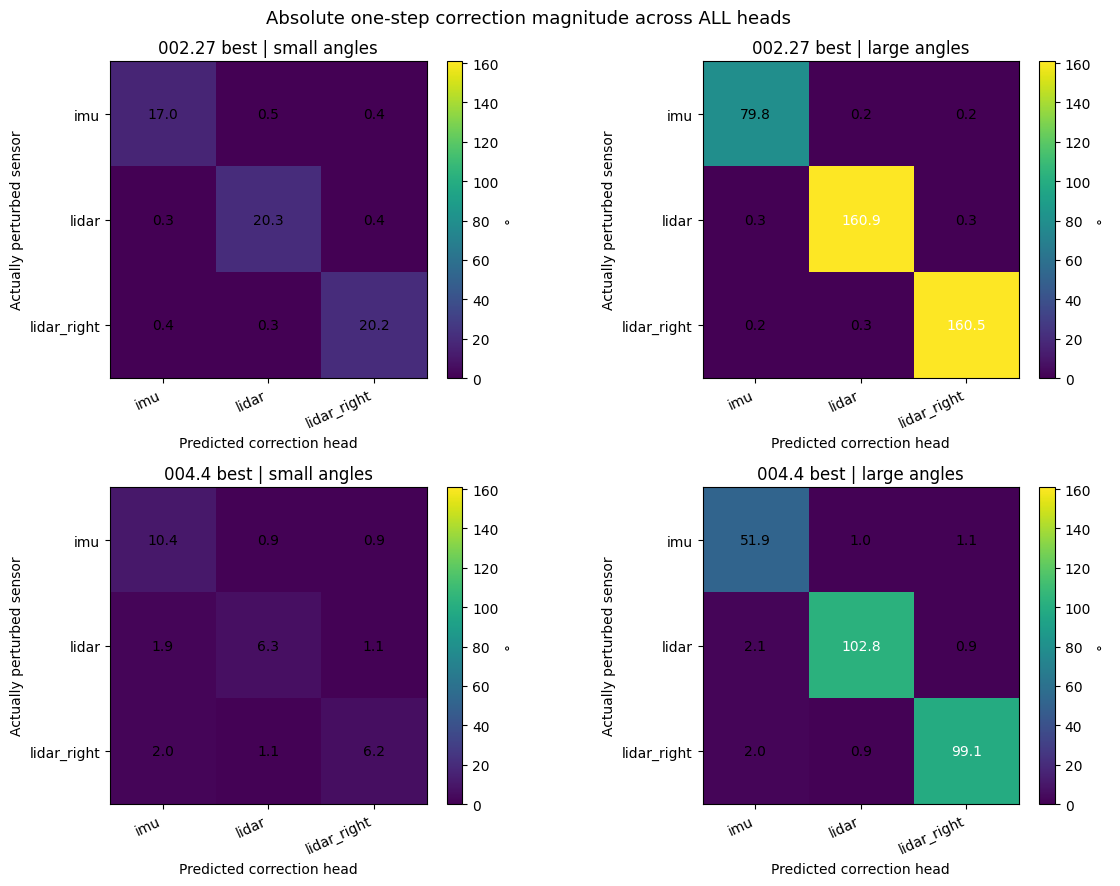

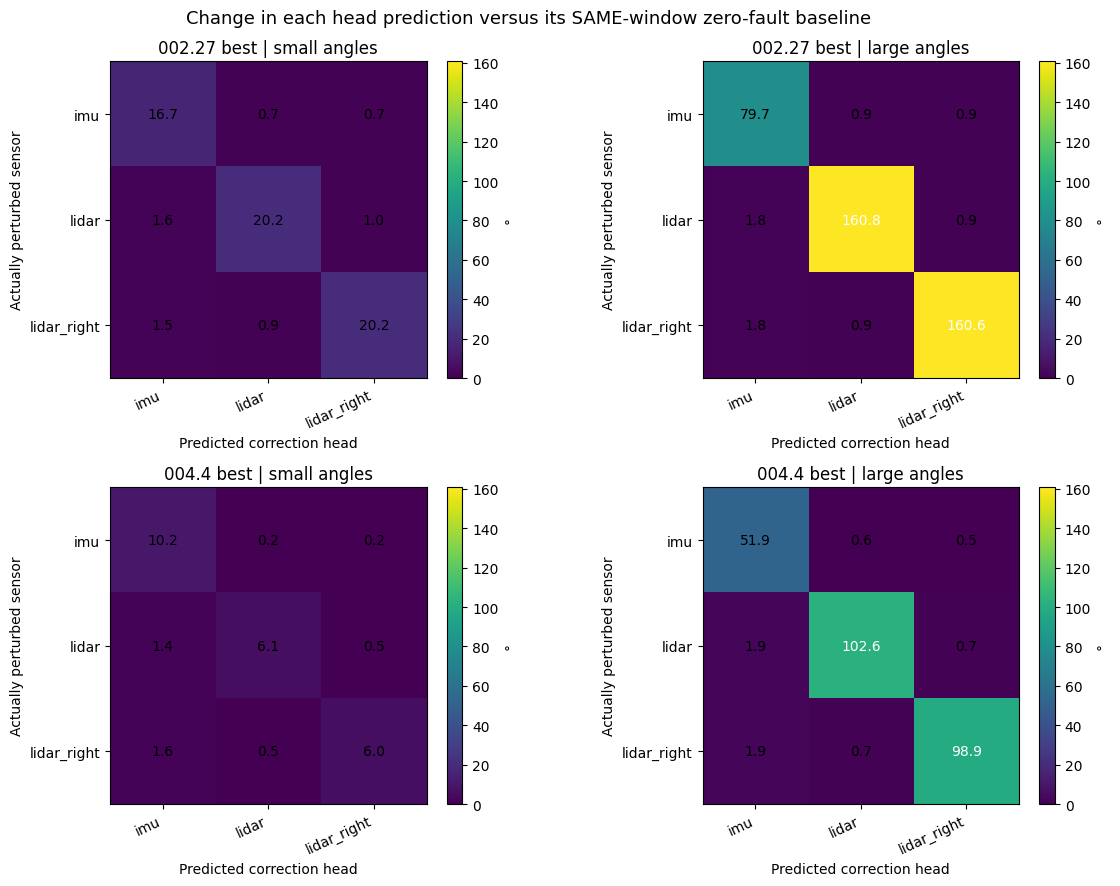

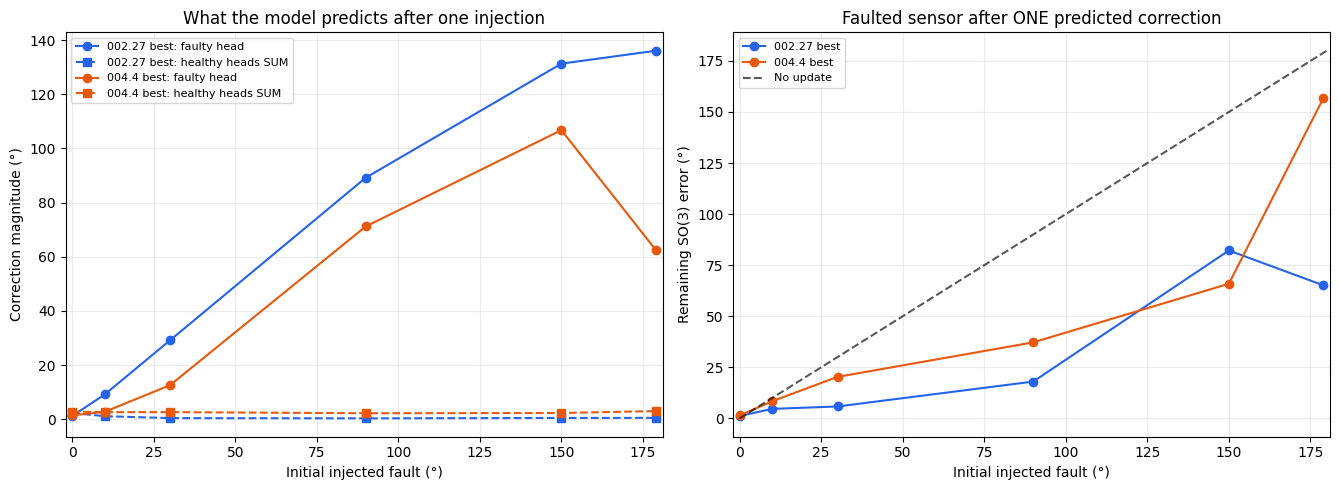


One-step sensor-specific leakage at small (10°/30°) and large (150°/179°) angles:


,model,injected_sensor,angle_group,n,faulty_rotation_deg,faulty_residual_deg,healthy_rotations_sum_deg,healthy_responses_sum_deg,healthy_raw_share,healthy_response_share,healthy_abs_tau_ms,healthy_tau_change_ms,healthy_translation_norm_m,healthy_translation_change_m
0,002.27 best,imu,large,32,79.761,150.458,0.330,1.774,0.004,0.022,0.312,9.691,0.000,0.000
1,002.27 best,imu,small,32,16.970,6.521,0.899,1.434,0.156,0.172,3.529,6.588,0.001,0.000
2,002.27 best,lidar,large,32,160.918,35.022,0.559,2.663,0.003,0.016,0.317,6.527,0.000,0.000
3,002.27 best,lidar,small,32,20.271,4.810,0.729,2.551,0.052,0.126,0.434,6.274,0.000,0.000
4,002.27 best,lidar_right,large,32,160.488,35.459,0.568,2.631,0.004,0.016,0.413,3.837,0.000,0.000
5,002.27 best,lidar_right,small,32,20.235,4.336,0.668,2.461,0.043,0.117,0.273,3.689,0.000,0.000
6,004.4 best,imu,large,32,51.879,161.716,2.105,1.110,0.039,0.021,1.755,5.519,0.002,0.001
7,004.4 best,imu,small,32,10.440,14.434,1.775,0.465,0.180,0.042,4.528,2.044,0.001,0.000
8,004.4 best,lidar,large,32,102.771,84.834,2.947,2.671,0.039,0.033,8.150,5.858,0.001,0.000
9,004.4 best,lidar,small,32,6.288,14.282,2.982,1.898,0.458,0.384,10.193,7.777,0.001,0.000



Interpretation: off-diagonal raw magnitude = nonzero corrections for initially healthy sensors. Off-diagonal response = their predictions CHANGE because another sensor was perturbed. These are NOT the same measurement. Inspect the zero-angle rows for baseline drift, and the time/translation columns for responses in those other DoFs. 
Appendix outputs: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/checkpoint_comparison_00227_best_vs_0044_best/validation/appendix_all_head_one_step


In [17]:
# A4. Plots: full 3x3 sensor-to-head matrix, baseline-subtracted response, and residuals.
# Only one-step predictions are made here; no feedback/rollout is involved.


def appendix_plot_heatmap(metric, title, basename, unit='°'):
    # Rows = faulted sensor. Columns = head the model predicts for.
    fig, axes = plt.subplots(len(MODEL_ORDER), 2, figsize=(12.0, 9.0), squeeze=False)
    subset = appendix_head_df[appendix_head_df.angle_group.isin(('small', 'large'))]
    vmax = float(subset.groupby(['model','angle_group','injected_sensor','predicted_head'])[metric].mean().max())
    vmax = max(vmax, 1e-8)
    for i, model_name in enumerate(MODEL_ORDER):
        for j, group in enumerate(('small', 'large')):
            data = appendix_head_df[(appendix_head_df.model==model_name) & (appendix_head_df.angle_group==group)]
            means = data.pivot_table(index='injected_sensor', columns='predicted_head', values=metric, aggfunc='mean')
            means = means.reindex(index=CALIBRATION_KEYS, columns=CALIBRATION_KEYS)
            values = means.to_numpy(dtype=float)
            image = axes[i,j].imshow(values, cmap='viridis', vmin=0, vmax=vmax)
            axes[i,j].set_xticks(range(len(CALIBRATION_KEYS)), CALIBRATION_KEYS, rotation=25, ha='right')
            axes[i,j].set_yticks(range(len(CALIBRATION_KEYS)), CALIBRATION_KEYS)
            axes[i,j].set_xlabel('Predicted correction head')
            axes[i,j].set_ylabel('Actually perturbed sensor')
            axes[i,j].set_title(f'{model_name} | {group} angles')
            for r in range(len(CALIBRATION_KEYS)):
                for c in range(len(CALIBRATION_KEYS)):
                    value = values[r,c]
                    if np.isfinite(value):
                        axes[i,j].text(c,r,f'{value:.1f}',ha='center',va='center',
                                       color='white' if value > 0.55*vmax else 'black',fontsize=10)
            fig.colorbar(image, ax=axes[i,j], fraction=0.045, pad=0.04, label=unit)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    if APPENDIX_SAVE_RESULTS:
        fig.savefig(APPENDIX_OUTPUT_DIR / basename, dpi=PLOT_DPI, bbox_inches='tight')
    if APPENDIX_SHOW_FIGURES:
        plt.show()
    else:
        plt.close(fig)


appendix_plot_heatmap('predicted_rotation_deg', 'Absolute one-step correction magnitude across ALL heads',
                      'all_head_raw_rotation_heatmaps.png')
appendix_plot_heatmap('response_from_clean_deg',
                      'Change in each head prediction versus its SAME-window zero-fault baseline',
                      'all_head_baseline_subtracted_response_heatmaps.png')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0), sharex=True)
for model_name in MODEL_ORDER:
    d = appendix_summary[appendix_summary.model==model_name].sort_values('angle_deg')
    axes[0].plot(d.angle_deg, d.fault_pred_deg, '-o', color=COLORS[model_name], label=f'{model_name}: faulty head')
    axes[0].plot(d.angle_deg, d.healthy_pred_sum_deg, '--s', color=COLORS[model_name],
                 label=f'{model_name}: healthy heads SUM')
    axes[1].plot(d.angle_deg, d.fault_left_deg, '-o', color=COLORS[model_name],label=model_name)
axes[0].set(title='What the model predicts after one injection', ylabel='Correction magnitude (°)')
axes[1].plot([0,180],[0,180],'k--',alpha=0.65,label='No update')
axes[1].set(title='Faulted sensor after ONE predicted correction', ylabel='Remaining SO(3) error (°)')
for ax in axes:
    ax.set(xlabel='Initial injected fault (°)',xlim=(-2,181))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
if APPENDIX_SAVE_RESULTS:
    fig.savefig(APPENDIX_OUTPUT_DIR / 'all_head_magnitudes_and_fault_residual.png', dpi=PLOT_DPI, bbox_inches='tight')
if APPENDIX_SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

print('\nOne-step sensor-specific leakage at small (10°/30°) and large (150°/179°) angles:')
appendix_sensor_summary = appendix_case_df[appendix_case_df.angle_group.isin(('small','large'))].groupby(
    ['model','injected_sensor','angle_group'],as_index=False).agg(
    n=('fault_rotation_deg','size'), faulty_rotation_deg=('fault_rotation_deg','mean'),
    faulty_residual_deg=('fault_residual_deg','mean'), healthy_rotations_sum_deg=('healthy_rotation_sum_deg','mean'),
    healthy_responses_sum_deg=('healthy_response_sum_deg','mean'),
    healthy_raw_share=('healthy_raw_fraction','mean'),
    healthy_response_share=('healthy_response_fraction','mean'),
    healthy_abs_tau_ms=('healthy_tau_abs_mean_ms','mean'),
    healthy_tau_change_ms=('healthy_tau_response_mean_ms','mean'),
    healthy_translation_norm_m=('healthy_translation_norm_mean_m','mean'),
    healthy_translation_change_m=('healthy_translation_response_mean_m','mean'))
display(appendix_sensor_summary.round(3))
if APPENDIX_SAVE_RESULTS:
    appendix_sensor_summary.to_csv(APPENDIX_OUTPUT_DIR / 'one_step_sensor_leakage_summary.csv', index=False)

print('\nInterpretation: off-diagonal raw magnitude = nonzero corrections for initially healthy sensors. '
      'Off-diagonal response = their predictions CHANGE because another sensor was perturbed. '
      'These are NOT the same measurement. Inspect the zero-angle rows for baseline drift, '
      'and the time/translation columns for responses in those other DoFs. ')
print('Appendix outputs:', APPENDIX_OUTPUT_DIR)